<a href="https://colab.research.google.com/github/AmyMugeni/Simulens/blob/ML-dataset-processing/Cognilens_ML_Pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Simulens system
 A machine learning model to predict user social media behaviour, Identify progressive compulsive social media use and deliver intervention prompts and educational insights against such use.

The model draws on contextual information provided by the user such as BSMAS score, weekly schedule and circardian rhythm.
By the use of Android APIs, the ML model uses session frequency, screen time, most app used, schedule conflicts, time of usage, session duration and session gaps to determine whether a session is intentional or not.

The model derives an average baseline from each user and monitores both + and - derivations and applies contextual information to deliver interventions.

# 1: Mounting Google Drive

In [1]:
from google.colab import drive
import os

drive.mount('/content/drive')

project_path = '/content/drive/MyDrive/Cognilens_MLtraining'
os.makedirs(project_path, exist_ok=True)
os.chdir(project_path)

print(f"Working directory set to: {os.getcwd()}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Working directory set to: /content/drive/MyDrive/Cognilens_MLtraining


## 2: Imports and Setup

In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import StratifiedKFold, GridSearchCV, train_test_split
from sklearn.metrics import classification_report, roc_auc_score, f1_score
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from xgboost import XGBClassifier


## 2. Data Loading and Initial Cleaning

In [3]:
import glob
import pandas as pd

# Find all files starting with 'SocialMediaUse'
file_pattern = 'SocialMediaUse*'
files = glob.glob(file_pattern)
print(f"Found {len(files)} files: {files}")

# Load and concatenate all matching CSV files
data_list = []
for file in files:
    try:
        df_temp = pd.read_csv(file)
        data_list.append(df_temp)
        print(f"Successfully loaded {file} with shape {df_temp.shape}")
    except Exception as e:
        print(f"Error loading {file}: {e}")

if data_list:
    df = pd.concat(data_list, ignore_index=True)
    print(f"Combined DataFrame shape: {df.shape}")

    # Columns specified for removal
    cols_to_drop = [
        'notification_count', 'triggered_by_notification',
        'scroll_count', 'scroll_speed_estimate', 'avg_scroll_delta_px',
        'micro_scrolls', 'normal_scrolls', 'macro_scrolls',
        'scroll_behavior', 'detected_format'
    ]

    # Drop columns that actually exist in the DataFrame
    existing_cols_to_drop = [col for col in cols_to_drop if col in df.columns]
    df = df.drop(columns=existing_cols_to_drop)
    print(f"Dropped {len(existing_cols_to_drop)} columns. New shape: {df.shape}")

    display(df.head())
    df.info()
else:
    print("No matching files found. Please ensure files starting with 'SocialMediaUse' exist in your Google Drive folder.")

Found 17 files: ['SocialMediaUse_export (4).csv', 'SocialMediaUse_export (2).csv', 'SocialMediaUse_export (3).csv', 'SocialMediaUse_export (1).csv', 'SocialMediaUse_export 5.csv', 'SocialMediaUse_export 6.csv', 'SocialMediaUse_export.csv', 'SocialMediaUse_export 7.csv', 'SocialMediaUse_export 8.csv', 'SocialMediaUse_export 9.csv', 'SocialMediaUse_export 10.csv', 'SocialMediaUse_export 11.csv', 'SocialMediaUse_export 15.csv', 'SocialMediaUse_export 14.csv', 'SocialMediaUse_export 13.csv', 'SocialMediaUse_export 16.csv', 'SocialMediaUse_export 17.csv']
Successfully loaded SocialMediaUse_export (4).csv with shape (502, 26)
Successfully loaded SocialMediaUse_export (2).csv with shape (708, 26)
Successfully loaded SocialMediaUse_export (3).csv with shape (171, 26)
Successfully loaded SocialMediaUse_export (1).csv with shape (645, 26)
Successfully loaded SocialMediaUse_export 5.csv with shape (183, 26)
Successfully loaded SocialMediaUse_export 6.csv with shape (307, 26)
Successfully loaded S

,user_id,session_start,session_end,date,day_of_week,session_hour,time_of_day,app_label,duration_minutes,tap_count,minutes_since_last_session,day_asi_score,day_intensity_score,day_fragmentation_score,day_compulsion_score,day_disruption_score
0,46b5fe4a-2c09-4006-bd5b-08bf12ece5e4,1790281329502,1790281593063,2026-09-24,Thursday,23,night,Instagram,4.39,0,28.47,48,45,68,32,49
1,46b5fe4a-2c09-4006-bd5b-08bf12ece5e4,1790279631154,1790279723216,2026-09-24,Thursday,22,night,YouTube,1.53,0,33.34,48,45,68,32,49
2,46b5fe4a-2c09-4006-bd5b-08bf12ece5e4,1790279484659,1790279621543,2026-09-24,Thursday,22,night,Instagram,2.28,0,7.95,48,45,68,32,49
3,46b5fe4a-2c09-4006-bd5b-08bf12ece5e4,1790278804601,1790279007621,2026-09-24,Thursday,22,night,Instagram,3.38,2,2.64,48,45,68,32,49
4,46b5fe4a-2c09-4006-bd5b-08bf12ece5e4,1790278538451,1790278646464,2026-09-24,Thursday,22,night,Instagram,1.80,0,0.00,48,45,68,32,49


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12892 entries, 0 to 12891
Data columns (total 16 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   user_id                     12892 non-null  object 
 1   session_start               12892 non-null  int64  
 2   session_end                 12892 non-null  int64  
 3   date                        12892 non-null  object 
 4   day_of_week                 12892 non-null  object 
 5   session_hour                12892 non-null  int64  
 6   time_of_day                 12892 non-null  object 
 7   app_label                   12892 non-null  object 
 8   duration_minutes            12892 non-null  float64
 9   tap_count                   12892 non-null  int64  
 10  minutes_since_last_session  12837 non-null  float64
 11  day_asi_score               12892 non-null  int64  
 12  day_intensity_score         12892 non-null  int64  
 13  day_fragmentation_score     128

### 3. Data Inspection, Duplicates, and Overlapping Sessions
In this step, we will check for identical row duplicates and identify sessions for individual users that overlap in time (where a session starts before the previous one ends).

In [4]:
# 1. Check for duplicate rows
duplicate_rows = df.duplicated().sum()
print(f"Total exact duplicate rows: {duplicate_rows}")

# 2. Check for overlapping sessions per user
# Sort by user and session start time
df_sorted = df.sort_values(by=['user_id', 'session_start']).copy()

# Identify overlaps: a session overlaps if its start time is strictly less than the previous session's end time for the same user
df_sorted['prev_session_end'] = df_sorted.groupby('user_id')['session_end'].shift(1)
df_sorted['is_overlapping'] = df_sorted['session_start'] < df_sorted['prev_session_end']

overlapping_count = df_sorted['is_overlapping'].sum()
print(f"Total overlapping sessions detected: {overlapping_count}")

if overlapping_count > 0:
    print("\nExample of overlapping sessions:")
    overlapping_examples = df_sorted[df_sorted['is_overlapping'] | df_sorted['is_overlapping'].shift(-1)]
    display(overlapping_examples[['user_id', 'session_start', 'session_end', 'app_label', 'duration_minutes']].head(10))
else:
    print("No overlapping sessions found.")

Total exact duplicate rows: 2932
Total overlapping sessions detected: 3803

Example of overlapping sessions:


,user_id,session_start,session_end,app_label,duration_minutes
8159,195f6f81-23c7-4fc7-88dd-2906f500aee9,1790968227560,1790968263875,Instagram,0.61
12891,195f6f81-23c7-4fc7-88dd-2906f500aee9,1790968227560,1790968263875,Instagram,0.61
8158,195f6f81-23c7-4fc7-88dd-2906f500aee9,1790968452965,1790968495206,Instagram,0.70
12890,195f6f81-23c7-4fc7-88dd-2906f500aee9,1790968452965,1790968495206,Instagram,0.70
8157,195f6f81-23c7-4fc7-88dd-2906f500aee9,1790970958366,1790971000345,Instagram,0.70
12889,195f6f81-23c7-4fc7-88dd-2906f500aee9,1790970958366,1790971000345,Instagram,0.70
8156,195f6f81-23c7-4fc7-88dd-2906f500aee9,1790971020285,1790971119437,Instagram,1.65
12888,195f6f81-23c7-4fc7-88dd-2906f500aee9,1790971020285,1790971119437,Instagram,1.65
8155,195f6f81-23c7-4fc7-88dd-2906f500aee9,1790971774656,1790971815631,Instagram,0.68
12887,195f6f81-23c7-4fc7-88dd-2906f500aee9,1790971774656,1790971815631,Instagram,0.68


### 4. Cleaning Duplicates and Re-evaluating Session Overlaps
Now we will clean up the dataset by removing exact duplicate rows first, then re-assess if there are any genuine temporal overlaps between distinct sessions.

In [5]:
# 1. Remove exact duplicate rows from the master dataframe
print(f"Shape before dropping duplicates: {df.shape}")
df = df.drop_duplicates()
print(f"Shape after dropping duplicates: {df.shape}")

# 2. Re-evaluate overlapping sessions on the cleaned dataset
df_sorted_clean = df.sort_values(by=['user_id', 'session_start']).copy()
df_sorted_clean['prev_session_end'] = df_sorted_clean.groupby('user_id')['session_end'].shift(1)
df_sorted_clean['is_overlapping'] = df_sorted_clean['session_start'] < df_sorted_clean['prev_session_end']

remaining_overlaps = df_sorted_clean['is_overlapping'].sum()
print(f"\nRemaining overlapping sessions after duplicate removal: {remaining_overlaps}")

if remaining_overlaps > 0:
    print("\nExamples of genuine overlapping sessions:")
    overlap_examples = df_sorted_clean[df_sorted_clean['is_overlapping'] | df_sorted_clean['is_overlapping'].shift(-1)]
    display(overlap_examples[['user_id', 'session_start', 'session_end', 'app_label', 'duration_minutes']].head(10))
else:
    print("No overlapping sessions remain!")

Shape before dropping duplicates: (12892, 16)
Shape after dropping duplicates: (9960, 16)

Remaining overlapping sessions after duplicate removal: 871

Examples of genuine overlapping sessions:


,user_id,session_start,session_end,app_label,duration_minutes
7740,195f6f81-23c7-4fc7-88dd-2906f500aee9,1791752536039,1791752567392,Instagram,0.52
12472,195f6f81-23c7-4fc7-88dd-2906f500aee9,1791752536039,1791752567392,Instagram,0.52
7739,195f6f81-23c7-4fc7-88dd-2906f500aee9,1791752691989,1791752745364,Instagram,0.89
12471,195f6f81-23c7-4fc7-88dd-2906f500aee9,1791752691989,1791752745364,Instagram,0.89
7738,195f6f81-23c7-4fc7-88dd-2906f500aee9,1791752786962,1791753007190,Instagram,3.67
12470,195f6f81-23c7-4fc7-88dd-2906f500aee9,1791752786962,1791753007190,Instagram,3.67
7737,195f6f81-23c7-4fc7-88dd-2906f500aee9,1791753012767,1791753050861,Instagram,0.63
12469,195f6f81-23c7-4fc7-88dd-2906f500aee9,1791753012767,1791753050861,Instagram,0.63
7736,195f6f81-23c7-4fc7-88dd-2906f500aee9,1791753102302,1791753409240,Instagram,5.12
12468,195f6f81-23c7-4fc7-88dd-2906f500aee9,1791753102302,1791753409240,Instagram,5.12


### 5. Deduplicating based on Unique Session Keys
Some sessions represent the exact same event but might differ slightly in computed fields. We will deduplicate based on `['user_id', 'session_start', 'session_end']` to ensure absolute uniqueness per session event.

In [6]:
# 1. Drop duplicates based on the primary session keys
print(f"Shape before session-key deduplication: {df.shape}")
df = df.drop_duplicates(subset=['user_id', 'session_start', 'session_end'])
print(f"Shape after session-key deduplication: {df.shape}")

# 2. Re-calculate genuine overlaps
df_sorted_clean = df.sort_values(by=['user_id', 'session_start']).copy()
df_sorted_clean['prev_session_end'] = df_sorted_clean.groupby('user_id')['session_end'].shift(1)
df_sorted_clean['is_overlapping'] = df_sorted_clean['session_start'] < df_sorted_clean['prev_session_end']

genuine_overlaps = df_sorted_clean['is_overlapping'].sum()
print(f"\nGenuine overlapping sessions remaining: {genuine_overlaps}")

if genuine_overlaps > 0:
    print("\nExamples of actual overlapping sessions (where start < previous end):")
    overlap_examples = df_sorted_clean[df_sorted_clean['is_overlapping'] | df_sorted_clean['is_overlapping'].shift(-1)]
    display(overlap_examples[['user_id', 'session_start', 'session_end', 'app_label', 'duration_minutes']].head(10))
else:
    print("No overlapping sessions remain!")

Shape before session-key deduplication: (9960, 16)
Shape after session-key deduplication: (9335, 16)

Genuine overlapping sessions remaining: 246

Examples of actual overlapping sessions (where start < previous end):


,user_id,session_start,session_end,app_label,duration_minutes
915,85bfc215-c24f-4814-aa00-6794f1a7278a,1777835435588,1777835574043,Instagram,2.31
914,85bfc215-c24f-4814-aa00-6794f1a7278a,1777835498000,1777835530000,Instagram,0.53
911,85bfc215-c24f-4814-aa00-6794f1a7278a,1777836062457,1777838251607,Instagram,36.49
910,85bfc215-c24f-4814-aa00-6794f1a7278a,1777836222000,1777836271000,Instagram,0.82
902,85bfc215-c24f-4814-aa00-6794f1a7278a,1777865312196,1777865460460,Instagram,2.47
901,85bfc215-c24f-4814-aa00-6794f1a7278a,1777865454000,1777888271000,Instagram,380.28
884,85bfc215-c24f-4814-aa00-6794f1a7278a,1778008246942,1778008931441,Instagram,11.41
883,85bfc215-c24f-4814-aa00-6794f1a7278a,1778008342000,1778008404000,Instagram,1.03
878,85bfc215-c24f-4814-aa00-6794f1a7278a,1778009684514,1778009855102,Instagram,2.84
877,85bfc215-c24f-4814-aa00-6794f1a7278a,1778009847000,1778012017000,Instagram,36.17


### 6. Merging Overlapping Sessions
We will group the data by `user_id` and merge chronologically overlapping sessions into single unified sessions, recalculating timestamps and session durations.

In [7]:
def merge_user_sessions(group):
    # Sort the group by session_start
    group = group.sort_values('session_start')

    merged = []
    for _, row in group.iterrows():
        if not merged:
            merged.append(row.to_dict())
        else:
            prev = merged[-1]
            # Overlap condition: current start <= previous end
            if row['session_start'] <= prev['session_end']:
                # Merge by extending the end time of the previous session if needed
                prev['session_end'] = max(prev['session_end'], row['session_end'])
                # Accumulate quantitative values
                prev['tap_count'] += row['tap_count']
                # Re-calculate duration based on the new interval
                # Timestamps are in milliseconds, duration_minutes = ms / 60000
                prev['duration_minutes'] = round((prev['session_end'] - prev['session_start']) / 60000.0, 2)
            else:
                merged.append(row.to_dict())

    return pd.DataFrame(merged)

print(f"Original shape before merging: {df.shape}")

# Group by user and apply the merge algorithm
df_merged = df.groupby('user_id', as_index=False, group_keys=False).apply(merge_user_sessions)

print(f"New shape after merging overlapping sessions: {df_merged.shape}")

# Update our master dataframe variable
df = df_merged.reset_index(drop=True)

# Re-verify if any overlapping sessions remain
df_sorted_clean = df.sort_values(by=['user_id', 'session_start']).copy()
df_sorted_clean['prev_session_end'] = df_sorted_clean.groupby('user_id')['session_end'].shift(1)
df_sorted_clean['is_overlapping'] = df_sorted_clean['session_start'] < df_sorted_clean['prev_session_end']

print(f"Overlapping sessions remaining: {df_sorted_clean['is_overlapping'].sum()}")
display(df.head())

Original shape before merging: (9335, 16)
New shape after merging overlapping sessions: (9065, 16)
Overlapping sessions remaining: 0


/tmp/ipykernel_8309/725456277.py:28: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_merged = df.groupby('user_id', as_index=False, group_keys=False).apply(merge_user_sessions)


,user_id,session_start,session_end,date,day_of_week,session_hour,time_of_day,app_label,duration_minutes,tap_count,minutes_since_last_session,day_asi_score,day_intensity_score,day_fragmentation_score,day_compulsion_score,day_disruption_score
0,195f6f81-23c7-4fc7-88dd-2906f500aee9,1790968227560,1790968263875,2026-10-02,Friday,22,night,Instagram,0.61,0,NaN,38,4,41,57,60
1,195f6f81-23c7-4fc7-88dd-2906f500aee9,1790968452965,1790968495206,2026-10-02,Friday,22,night,Instagram,0.70,0,3.15,38,4,41,57,60
2,195f6f81-23c7-4fc7-88dd-2906f500aee9,1790970958366,1790971000345,2026-10-02,Friday,22,night,Instagram,0.70,0,41.05,38,4,41,57,60
3,195f6f81-23c7-4fc7-88dd-2906f500aee9,1790971020285,1790971119437,2026-10-02,Friday,22,night,Instagram,1.65,0,0.33,38,4,41,57,60
4,195f6f81-23c7-4fc7-88dd-2906f500aee9,1790971774656,1790971815631,2026-10-02,Friday,23,night,Instagram,0.68,0,10.92,38,4,41,57,60


### 7. Load and Inspect Timetable Datasets
We will scan the directory to find the timetable files (`final_timetable.csv` and the other Excel/CSV starting with `bics_4a_apr_July`), load them to inspect their columns, and prepare them for mapping.

In [8]:
import os
import glob
import pandas as pd

# Find timetable files
timetable_files = glob.glob('*timetable*') + glob.glob('*bics*')
print("Found files matching timetable patterns:", timetable_files)

# Let's inspect the files found
for file in timetable_files:
    try:
        if file.endswith('.csv'):
            temp_df = pd.read_csv(file)
        else:
            temp_df = pd.read_excel(file)
        print(f"\nFile: {file} | Shape: {temp_df.shape}")
        print("Columns:", temp_df.columns.tolist())
        display(temp_df.head(3))
    except Exception as e:
        print(f"Error reading {file}: {e}")

Found files matching timetable patterns: ['final_timetable.csv', 'bics_4a_apr_jul_2026.csv']

File: final_timetable.csv | Shape: (5, 10)
Columns: ['Day', '8.15 - 9.15', '9.15 – 10.15', '10.15 – 11.15', '11.15 – 12.15', '12.15 - 1.15', '1.15 - 2.15', '2.15 – 3.15', '3.15 – 4.15', '4.15 - 5.15']


,Day,8.15 - 9.15,9.15 – 10.15,10.15 – 11.15,11.15 – 12.15,12.15 - 1.15,1.15 - 2.15,2.15 – 3.15,3.15 – 4.15,4.15 - 5.15
0,Monday,ICS | Computing and | LT,4212 | Business Law | 1,-,Maisha Program 8 | Ladies STM B B 03,ICS | Computer | Meeting ID: 374 | Passcode:,3205 | Graphic | 798 961 774 348 | wq9BT73M,-,ICS | ICS | MSB,4101 | Project II | 4
1,Tuesday,G Wasonga | ICS | ICS Project | Meeting ID: 33...,4101 | II | 292 383 153 21 | my74JL7a,ICS 4212 | Computing and | Business Law | Meet...,R Bunde,Z | ICS 4201 | Compiler | LT,Muti | Construction | 6,ICS | Information Systems | LT,K | 4203 | Security and Design | 3,Omondi
2,Wednesday,K Omondi,ICS | Compiler | Meeting ID: | Passcode:,G Wasonga | 4201 | Construction | 352 281 059 ...,ICS 4212 | Corporate Governance | and Sustaina...,K,Ouma | ICS | Information Systems | Meeting ID:...,J | 4203 | Security and Design | 664 371 574 5...,Mutahi,ICS 4301 | Computing for | Bioinformatics | Me...



File: bics_4a_apr_jul_2026.csv | Shape: (17, 4)
Columns: ['day', 'start_time', 'end_time', 'activity']


,day,start_time,end_time,activity
0,Monday,08:15,10:15,ICS 4106 - Computer Simulation and Modelling
1,Monday,10:15,12:15,ICS 4102 - Machine Learning
2,Monday,13:15,14:15,ICS 4103 - Cloud Computing


### 8. Normalize Timetables and Map Schedule Conflicts
We will combine the schedules from `final_timetable.csv` and `bics_4a_apr_jul_2026.csv` into a clean, standardized format. Then, we will map each social media session to determine if it overlaps with any scheduled class or activity slot.

In [9]:
import datetime

# 1. Parse 'bics_4a_apr_jul_2026.csv'
bics_df = pd.read_csv('bics_4a_apr_jul_2026.csv')
schedule_list = []

# Clean weekday names to standard capitalized forms
def clean_day(day_str):
    return str(day_str).strip().capitalize()

for _, row in bics_df.iterrows():
    day = clean_day(row['day'])
    start_time = row['start_time'].strip()
    end_time = row['end_time'].strip()
    activity = str(row['activity']).strip()
    # Avoid adding entries that are free/sports/empty if they do not represent a conflict
    if activity and activity != '-' and 'free' not in activity.lower():
        schedule_list.append({
            'day': day,
            'start_time': start_time,
            'end_time': end_time,
            'activity': activity
        })

# 2. Parse 'final_timetable.csv' (Wide Format)
final_tt_df = pd.read_csv('final_timetable.csv')
time_cols = [c for c in final_tt_df.columns if c != 'Day']

# Helper to standardize dash and spaces in times
def parse_time_range(col_name):
    # Replaces varied dashes with standard hyphen
    col_cleaned = col_name.replace('–', '-').replace(' ', '')
    start, end = col_cleaned.split('-')
    # Standardize to HH:MM
    def format_hm(t_str):
        parts = t_str.split('.')
        h = int(parts[0])
        m = int(parts[1]) if len(parts) > 1 else 0
        # Standardize 12-hour values after 8.15 to PM if they are smaller than 8 (e.g. 1.15 -> 13:15)
        if h < 8:
            h += 12
        return f"{h:02d}:{m:02d}"
    return format_hm(start), format_hm(end)

for _, row in final_tt_df.iterrows():
    day = clean_day(row['Day'])
    for col in time_cols:
        cell_val = str(row[col]).strip()
        if cell_val and cell_val != '-' and cell_val.lower() != 'nan':
            try:
                start_t, end_t = parse_time_range(col)
                schedule_list.append({
                    'day': day,
                    'start_time': start_t,
                    'end_time': end_t,
                    'activity': cell_val
                })
            except Exception as e:
                print(f"Skipping cell parse due to error: {e} in column {col}")

schedules_df = pd.DataFrame(schedule_list)
print(f"Normalized schedules: {schedules_df.shape[0]} slots active.")
display(schedules_df.head(10))

# 3. Define function to check schedule conflicts
def has_conflict(row):
    # Extract day and time
    # session_start is in milliseconds. Convert to datetime
    session_dt = datetime.datetime.fromtimestamp(row['session_start'] / 1000.0, tz=datetime.timezone.utc)
    day_name = session_dt.strftime('%A')
    session_time_str = session_dt.strftime('%H:%M')

    # Check matching day in schedule
    day_schedules = schedules_df[schedules_df['day'] == day_name]
    for _, sched in day_schedules.iterrows():
        if sched['start_time'] <= session_time_str <= sched['end_time']:
            return 1
    return 0

# Map schedule conflicts
print("Mapping schedule conflicts onto session data...")
df['schedule_conflict'] = df.apply(has_conflict, axis=1)

print("Distribution of schedule conflicts:")
print(df['schedule_conflict'].value_counts())
display(df[['session_start', 'day_of_week', 'schedule_conflict']].head(10))

Normalized schedules: 56 slots active.


,day,start_time,end_time,activity
0,Monday,08:15,10:15,ICS 4106 - Computer Simulation and Modelling
1,Monday,10:15,12:15,ICS 4102 - Machine Learning
2,Monday,13:15,14:15,ICS 4103 - Cloud Computing
3,Monday,15:15,17:15,ICS 3105 - Multimedia Applications
4,Tuesday,08:15,10:15,ICS 4101 - ICS Project II
5,Tuesday,10:15,11:15,Maisha Program 7 - Gents 4A
6,Tuesday,11:15,12:15,Maisha Program 7 - Ladies ICS 4A
7,Tuesday,13:15,15:15,ICS 4104 - Distributed Systems
8,Wednesday,08:15,10:15,ICS 4111 - Embedded Systems and Internet of Th...
9,Wednesday,11:15,12:15,ICS 4106 - Computer Simulation and Modelling


Mapping schedule conflicts onto session data...
Distribution of schedule conflicts:
schedule_conflict
0    5913
1    3152
Name: count, dtype: int64


,session_start,day_of_week,schedule_conflict
0,1790968227560,Friday,0
1,1790968452965,Friday,0
2,1790970958366,Friday,0
3,1790971020285,Friday,0
4,1790971774656,Friday,0
5,1791010528273,Saturday,0
6,1791010622414,Saturday,0
7,1791011469356,Saturday,0
8,1791011847278,Saturday,0
9,1791012743055,Saturday,0


### 9. Configure Sleep/Wake Schedule Conflicts
We will define a global sleep schedule where the hours between midnight (00:00) and 06:00 AM are designated as sleeping hours. Any session that falls within these hours will be flagged with a schedule conflict (`schedule_conflict = 1`).

In [10]:
import datetime

def check_sleep_and_schedule_conflict(row):
    # 1. Parse session time
    session_dt = datetime.datetime.fromtimestamp(row['session_start'] / 1000.0, tz=datetime.timezone.utc)
    day_name = session_dt.strftime('%A')
    session_time_str = session_dt.strftime('%H:%M')
    hour = session_dt.hour

    # 2. Check sleep-time conflict (12:00 AM / 00:00 to 06:00 AM)
    if 0 <= hour < 6:
        return 1

    # 3. Check existing timetable schedule conflict
    day_schedules = schedules_df[schedules_df['day'] == day_name]
    for _, sched in day_schedules.iterrows():
        if sched['start_time'] <= session_time_str <= sched['end_time']:
            return 1

    return 0

# Map the updated conflict status containing sleep times
print("Updating schedule conflicts to incorporate the 12:00 AM - 06:00 AM sleep schedule...")
df['schedule_conflict'] = df.apply(check_sleep_and_schedule_conflict, axis=1)

print("New distribution of schedule conflicts (including sleep time active sessions):")
print(df['schedule_conflict'].value_counts())
display(df[['session_start', 'session_hour', 'day_of_week', 'schedule_conflict']].head(15))

Updating schedule conflicts to incorporate the 12:00 AM - 06:00 AM sleep schedule...
New distribution of schedule conflicts (including sleep time active sessions):
schedule_conflict
0    4892
1    4173
Name: count, dtype: int64


,session_start,session_hour,day_of_week,schedule_conflict
0,1790968227560,22,Friday,0
1,1790968452965,22,Friday,0
2,1790970958366,22,Friday,0
3,1790971020285,22,Friday,0
4,1790971774656,23,Friday,0
5,1791010528273,9,Saturday,0
6,1791010622414,9,Saturday,0
7,1791011469356,10,Saturday,0
8,1791011847278,10,Saturday,0
9,1791012743055,10,Saturday,0


### 10. Data Visualization
We will visualize the session data to analyze the distributions of our key features, including the newly mapped schedule conflicts and user hourly activity patterns.

/tmp/ipykernel_8309/2886153233.py:35: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1, 1].set_xticklabels(axes[1, 1].get_xticklabels(), rotation=30)


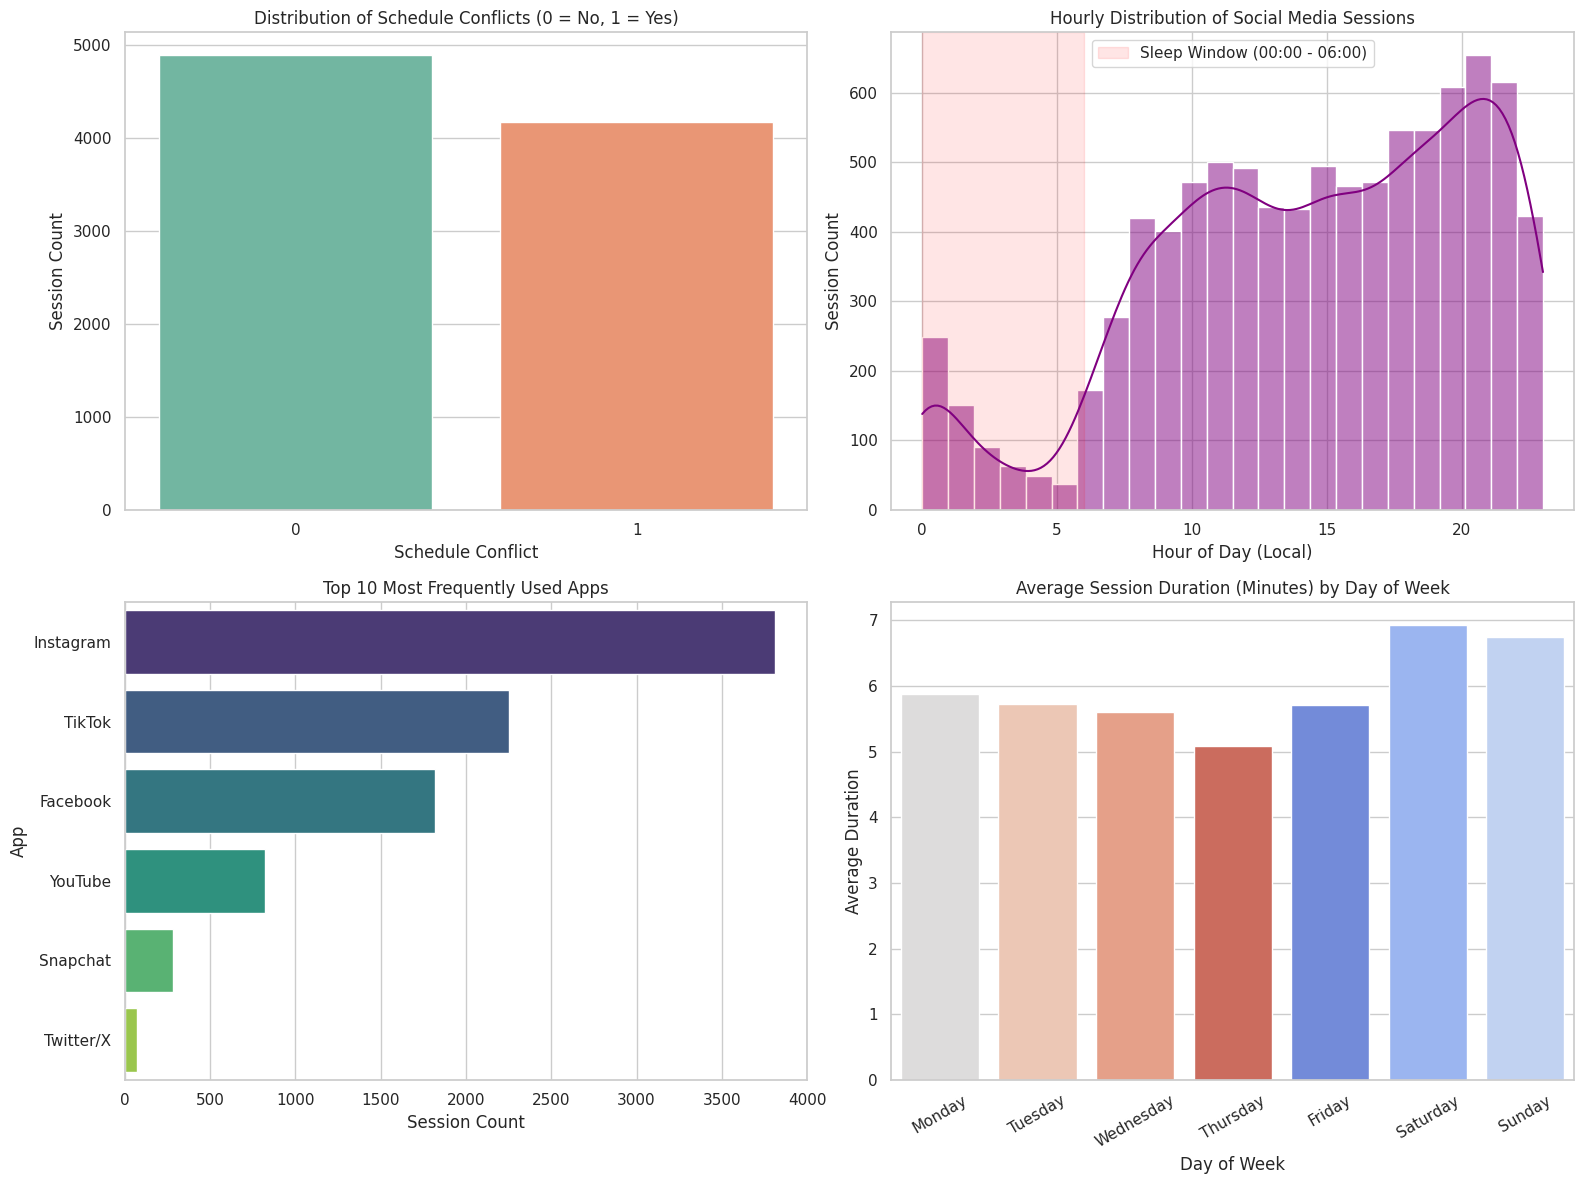

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set the aesthetic style for the plots
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Distribution of Schedule Conflicts
sns.countplot(ax=axes[0, 0], data=df, x='schedule_conflict', palette='Set2', hue='schedule_conflict', legend=False)
axes[0, 0].set_title('Distribution of Schedule Conflicts (0 = No, 1 = Yes)')
axes[0, 0].set_xlabel('Schedule Conflict')
axes[0, 0].set_ylabel('Session Count')

# 2. Hourly Distribution of Sessions
sns.histplot(ax=axes[0, 1], data=df, x='session_hour', bins=24, kde=True, color='purple')
axes[0, 1].set_title('Hourly Distribution of Social Media Sessions')
axes[0, 1].set_xlabel('Hour of Day (Local)')
axes[0, 1].set_ylabel('Session Count')
axes[0, 1].axvspan(0, 6, color='red', alpha=0.1, label='Sleep Window (00:00 - 06:00)')
axes[0, 1].legend()

# 3. Top Most Used Apps
top_apps = df['app_label'].value_counts().head(10)
sns.barplot(ax=axes[1, 0], x=top_apps.values, y=top_apps.index, palette='viridis', hue=top_apps.index, legend=False)
axes[1, 0].set_title('Top 10 Most Frequently Used Apps')
axes[1, 0].set_xlabel('Session Count')
axes[1, 0].set_ylabel('App')

# 4. Average Session Duration by Day of Week
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
sns.barplot(ax=axes[1, 1], data=df, x='day_of_week', y='duration_minutes', order=day_order, palette='coolwarm', hue='day_of_week', legend=False, errorbar=None)
axes[1, 1].set_title('Average Session Duration (Minutes) by Day of Week')
axes[1, 1].set_xlabel('Day of Week')
axes[1, 1].set_ylabel('Average Duration')
axes[1, 1].set_xticklabels(axes[1, 1].get_xticklabels(), rotation=30)

plt.tight_layout()
plt.show()

### 11. Analyzing Average Daily Usage per User
We will group the dataset by `user_id` and `date` to find the total active duration per day, and then take the average over all days for each user.

Summary Statistics of Average Daily Social Media Usage per User (in minutes):


,avg_daily_duration_minutes
count,10.000000
mean,169.015855
std,80.094861
min,79.750000
25%,116.425125
50%,152.927530
75%,193.836349
max,340.777931


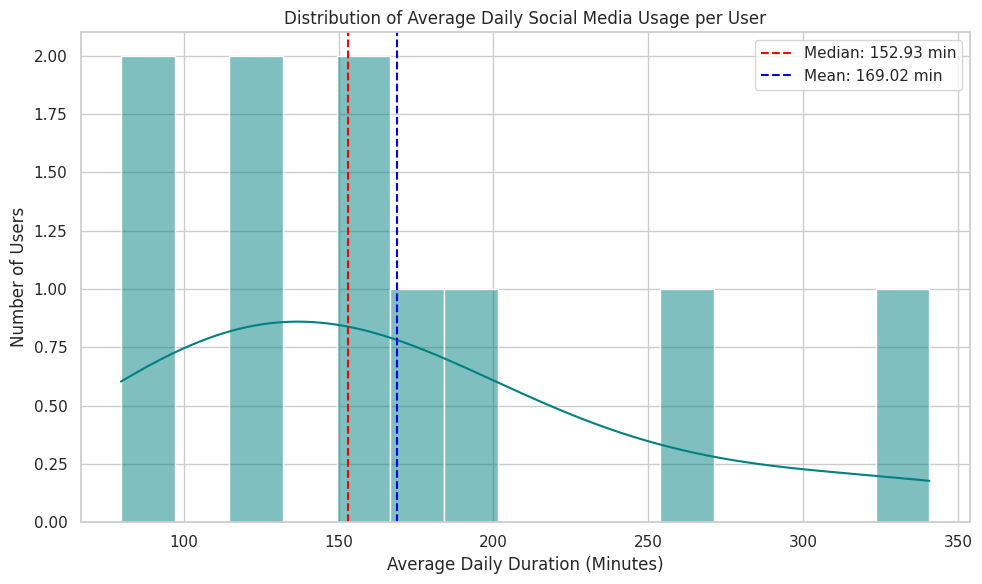

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Aggregate duration per user per day
daily_user_usage = df.groupby(['user_id', 'date'])['duration_minutes'].sum().reset_index()

# 2. Calculate the average daily usage per user
avg_daily_usage = daily_user_usage.groupby('user_id')['duration_minutes'].mean().reset_index()
avg_daily_usage.rename(columns={'duration_minutes': 'avg_daily_duration_minutes'}, inplace=True)

# Display summary statistics
print("Summary Statistics of Average Daily Social Media Usage per User (in minutes):")
display(avg_daily_usage['avg_daily_duration_minutes'].describe())

# 3. Visualize the distribution of average daily usage
plt.figure(figsize=(10, 6))
sns.histplot(data=avg_daily_usage, x='avg_daily_duration_minutes', kde=True, color='teal', bins=15)
plt.title('Distribution of Average Daily Social Media Usage per User')
plt.xlabel('Average Daily Duration (Minutes)')
plt.ylabel('Number of Users')
plt.axvline(avg_daily_usage['avg_daily_duration_minutes'].median(), color='red', linestyle='--', label=f"Median: {avg_daily_usage['avg_daily_duration_minutes'].median():.2f} min")
plt.axvline(avg_daily_usage['avg_daily_duration_minutes'].mean(), color='blue', linestyle='--', label=f"Mean: {avg_daily_usage['avg_daily_duration_minutes'].mean():.2f} min")
plt.legend()
plt.tight_layout()
plt.show()

### 16. Engineering User-Specific Baselines and Deviations

To align our model with the simulens system design, we will compute historical baseline metrics for each unique user and calculate session-by-session deviations. This shifts our model from a generic hourly classifier to a highly personalized behavioral detector.

In [13]:

import numpy as np
import pandas as pd


def generate_personal_baselines(
    df: pd.DataFrame,
    user_col: str = "user_id",
    timestamp_col: str = "timestamp",
    duration_col: str = "duration_minutes",
    gap_col: str = "minutes_since_last_session",
    window: str = "28D",
    min_history: int = 5,
) -> pd.DataFrame:
    """
    Generate per-user, past-only rolling session baselines.

    Each session baseline uses valid observations from the
    preceding time window, excluding the current observation.

    Duration:
      duration_deviation = current duration - historical median
      duration_increase = positive duration deviation only

    Gap:
      gap_deviation = historical median gap - current gap
      gap_reduction = positive gap reduction only
    """

    required = {
        user_col, timestamp_col, duration_col, gap_col
    }
    missing = required.difference(df.columns)

    if missing:
        raise ValueError(
            f"Missing required columns: {sorted(missing)}"
        )

    if min_history < 1:
        raise ValueError("min_history must be at least 1")

    window_delta = pd.Timedelta(window)
    if window_delta <= pd.Timedelta(0):
        raise ValueError("window must be positive")

    result = df.copy().reset_index(drop=True)

    result[timestamp_col] = pd.to_datetime(
        result[timestamp_col],
        errors="coerce",
        utc=True,
    )

    for col in [duration_col, gap_col]:
        result[col] = pd.to_numeric(
            result[col], errors="coerce"
        )
        result[col] = result[col].where(
            np.isfinite(result[col]) & (result[col] >= 0)
        )

    metrics = [duration_col, gap_col]

    for col in metrics:
        result[f"{col}_baseline_median"] = np.nan
        result[f"{col}_baseline_mean"] = np.nan
        result[f"{col}_baseline_count"] = 0

    # Original row order is retained in the returned DataFrame.
    # A stable sort makes tied timestamps deterministic.
    valid = result.dropna(
        subset=[user_col, timestamp_col]
    )

    for _, group in valid.groupby(user_col, sort=False):
        group = group.sort_values(
            timestamp_col, kind="mergesort"
        )

        times = group[timestamp_col]
        indices = group.index

        for col in metrics:
            values = group[col].to_numpy(dtype=float)

            medians = np.full(len(group), np.nan)
            means = np.full(len(group), np.nan)
            counts = np.zeros(len(group), dtype=int)

            # Strictly earlier timestamps only.
            # Sessions with tied timestamps are excluded from
            # one another's baselines to avoid arbitrary ordering.
            for i, current_time in enumerate(times):
                start_time = current_time - window_delta

                historical_mask = (
                    (times < current_time)
                    & (times >= start_time)
                ).to_numpy()

                historical = values[historical_mask]
                historical = historical[
                    np.isfinite(historical)
                ]

                counts[i] = len(historical)

                if counts[i] >= min_history:
                    medians[i] = np.median(historical)
                    means[i] = np.mean(historical)

            result.loc[
                indices, f"{col}_baseline_median"
            ] = medians

            result.loc[
                indices, f"{col}_baseline_mean"
            ] = means

            result.loc[
                indices, f"{col}_baseline_count"
            ] = counts

    duration_baseline = result[
        f"{duration_col}_baseline_median"
    ]
    gap_baseline = result[
        f"{gap_col}_baseline_median"
    ]

    # Duration deviation: positive means longer than usual.
    result["duration_deviation"] = (
        result[duration_col] - duration_baseline
    )
    result["duration_increase"] = (
        result["duration_deviation"].clip(lower=0)
    )

    result["duration_ratio"] = (
        result[duration_col]
        / duration_baseline.where(duration_baseline > 0)
    )

    # Gap deviation: positive means returning sooner than usual.
    result["gap_deviation"] = (
        gap_baseline - result[gap_col]
    )
    result["gap_reduction"] = (
        result["gap_deviation"].clip(lower=0)
    )

    result["gap_ratio"] = (
        result[gap_col]
        / gap_baseline.where(gap_baseline > 0)
    )

    result["duration_baseline_available"] = (
        result[f"{duration_col}_baseline_count"].ge(min_history)
        & duration_baseline.notna()
    )

    result["gap_baseline_available"] = (
        result[f"{gap_col}_baseline_count"].ge(min_history)
        & gap_baseline.notna()
    )

    result["baseline_available"] = (
        result["duration_baseline_available"]
        & result["gap_baseline_available"]
    )

    return result


VALIDATION AFTER GENERATING BASELINES

In [14]:
import pandas as pd

# Map or generate the timestamp column from session_start if not already present
if 'timestamp' not in df.columns:
    df['timestamp'] = pd.to_datetime(df['session_start'] / 1000.0, unit='s', utc=True)

# Call the function to compute the rolling personal baselines
df = generate_personal_baselines(
    df,
    user_col="user_id",
    timestamp_col="timestamp",
    duration_col="duration_minutes",
    gap_col="minutes_since_last_session",
    window="28D",
    min_history=5
)

# Confirm that baselines use prior data only.
print("Rows:", len(df))
print(
    "Duration baseline available:",
    int(df["duration_baseline_available"].sum())
)
print(
    "Gap baseline available:",
    int(df["gap_baseline_available"].sum())
)
print(
    "Both baselines available:",
    int(df["baseline_available"].sum())
)

# Ratios should be missing where their baseline is zero or absent.
assert df.loc[
    df["duration_minutes_baseline_median"].le(0)
    | df["duration_minutes_baseline_median"].isna(),
    "duration_ratio"
].isna().all()

assert df.loc[
    df["minutes_since_last_session_baseline_median"].le(0)
    | df["minutes_since_last_session_baseline_median"].isna(),
    "gap_ratio"
].isna().all()

display(
    df[
        [
            "user_id",
            "timestamp",
            "duration_minutes",
            "duration_minutes_baseline_median",
            "duration_deviation",
            "duration_increase",
            "minutes_since_last_session",
            "minutes_since_last_session_baseline_median",
            "gap_deviation",
            "gap_reduction",
            "duration_baseline_available",
            "gap_baseline_available",
        ]
    ].head(20)
)

Rows: 9065
Duration baseline available: 9010
Gap baseline available: 8994
Both baselines available: 8994


,user_id,timestamp,duration_minutes,duration_minutes_baseline_median,duration_deviation,duration_increase,minutes_since_last_session,minutes_since_last_session_baseline_median,gap_deviation,gap_reduction,duration_baseline_available,gap_baseline_available
0,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-02 19:10:27.559999943+00:00,0.61,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,False
1,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-02 19:14:12.964999914+00:00,0.70,NaN,NaN,NaN,3.15,NaN,NaN,NaN,False,False
2,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-02 19:55:58.365999937+00:00,0.70,NaN,NaN,NaN,41.05,NaN,NaN,NaN,False,False
3,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-02 19:57:00.285000086+00:00,1.65,NaN,NaN,NaN,0.33,NaN,NaN,NaN,False,False
4,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-02 20:09:34.655999899+00:00,0.68,NaN,NaN,NaN,10.92,NaN,NaN,NaN,False,False
5,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-03 06:55:28.273000002+00:00,1.03,0.700,0.330,0.330,645.21,NaN,NaN,NaN,True,False
6,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-03 06:57:02.414000034+00:00,13.49,0.700,12.790,12.790,0.54,10.920,10.380,10.380,True,True
7,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-03 07:11:09.355999947+00:00,5.81,0.700,5.110,5.110,0.63,7.035,6.405,6.405,True,True
8,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-03 07:17:27.278000116+00:00,14.08,0.865,13.215,13.215,0.49,3.150,2.660,2.660,True,True
9,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-03 07:32:23.055000067+00:00,3.70,1.030,2.670,2.670,0.85,1.890,1.040,1.040,True,True


RUN GENERATE BASELINES

In [15]:
import numpy as np
import pandas as pd

# Ensure daily_df exists by aggregating df if it hasn't been defined yet
if 'daily_df' not in globals():
    print("daily_df not found in kernel. Creating daily aggregation dynamically...")
    sessions = df.copy()
    sessions["timestamp"] = pd.to_datetime(sessions["timestamp"], errors="coerce", utc=True)
    sessions["duration_minutes"] = pd.to_numeric(sessions["duration_minutes"], errors="coerce")
    sessions = sessions.dropna(subset=["user_id", "timestamp", "duration_minutes"])
    sessions = sessions[sessions["duration_minutes"] > 0].copy()
    sessions["date"] = sessions["timestamp"].dt.date

    aggregations = {
        "session_count": ("duration_minutes", "size"),
        "total_duration_minutes": ("duration_minutes", "sum"),
        "median_session_duration": ("duration_minutes", "median"),
        "mean_session_duration": ("duration_minutes", "mean"),
    }
    if "minutes_since_last_session" in sessions.columns:
        sessions["minutes_since_last_session"] = pd.to_numeric(sessions["minutes_since_last_session"], errors="coerce")
        aggregations["mean_session_gap"] = ("minutes_since_last_session", "mean")
        aggregations["median_session_gap"] = ("minutes_since_last_session", "median")

    daily_df = (
        sessions
        .groupby(["user_id", "date"], as_index=False)
        .agg(**aggregations)
        .sort_values(["user_id", "date"])
        .reset_index(drop=True)
    )

# Ensure coverage_eligible column exists for the daily baseline function
if 'coverage_eligible' not in daily_df.columns:
    # Default to True so daily historical calculations can run
    daily_df['coverage_eligible'] = True


def generate_daily_baselines(
    daily_df: pd.DataFrame,
    user_col: str = "user_id",
    date_col: str = "date",
    duration_col: str = "total_duration_minutes",
    frequency_col: str = "session_count",
    window_days: int = 28,
    min_history_days: int = 5,
) -> pd.DataFrame:
    """
    Calculate past-only, per-user daily baselines.

    Only coverage-eligible historical days contribute to baselines.
    The current day is excluded from its own baseline.
    Positive increase features indicate values above the
    historical median.
    """

    required = {
        user_col, date_col, duration_col,
        frequency_col, "coverage_eligible"
    }
    missing = required.difference(daily_df.columns)

    if missing:
        raise ValueError(
            f"Missing required columns: {sorted(missing)}"
        )

    if window_days < 1 or min_history_days < 1:
        raise ValueError(
            "window_days and min_history_days must be positive."
        )

    result = daily_df.copy().reset_index(drop=True)

    result[date_col] = pd.to_datetime(
        result[date_col], errors="coerce"
    ).dt.normalize()

    if result.duplicated([user_col, date_col]).any():
        raise ValueError(
            "Duplicate user-day rows found. Resolve these before "
            "calculating daily baselines."
        )

    result["coverage_eligible"] = (
        result["coverage_eligible"]
        .fillna(False)
        .astype(bool)
    )

    for col in [duration_col, frequency_col]:
        result[col] = pd.to_numeric(
            result[col], errors="coerce"
        )
        result[col] = result[col].where(
            np.isfinite(result[col]) & (result[col] >= 0)
        )

    # An unreliable day's values must never enter the baseline.
    result.loc[
        ~result["coverage_eligible"],
        [duration_col, frequency_col]
    ] = np.nan

    # Average session duration is undefined for zero sessions.
    result["avg_session_duration_minutes"] = (
        result[duration_col]
        / result[frequency_col].where(
            result[frequency_col] > 0
        )
    )

    metrics = {
        duration_col: "daily_duration",
        frequency_col: "daily_frequency",
        "avg_session_duration_minutes": "daily_avg_session",
    }

    for col, prefix in metrics.items():
        result[f"{prefix}_baseline_median"] = np.nan
        result[f"{prefix}_baseline_mean"] = np.nan
        result[f"{prefix}_baseline_days"] = 0

    valid = result.dropna(
        subset=[user_col, date_col]
    )

    for _, group in valid.groupby(user_col, sort=False):
        group = group.sort_values(
            date_col, kind="mergesort"
        )

        dates = group[date_col]

        for col, prefix in metrics.items():
            values = group[col]

            medians = []
            means = []
            counts = []

            for current_date in dates:
                start_date = (
                    current_date
                    - pd.Timedelta(days=window_days)
                )

                history_mask = (
                    (dates < current_date)
                    & (dates >= start_date)
                )

                history = values.loc[history_mask].dropna()

                counts.append(len(history))

                if len(history) >= min_history_days:
                    medians.append(history.median())
                    means.append(history.mean())
                else:
                    medians.append(np.nan)
                    means.append(np.nan)

            result.loc[
                group.index,
                f"{prefix}_baseline_median"
            ] = medians

            result.loc[
                group.index,
                f"{prefix}_baseline_mean"
            ] = means

            result.loc[
                group.index,
                f"{prefix}_baseline_days"
            ] = counts

    # Absolute increases above the personal historical median.
    for prefix, source_col in metrics.items():
        baseline_col = f"{source_col}_baseline_median"

        result[f"{source_col}_deviation"] = (
            result[prefix] - result[baseline_col]
        )

        result[f"{source_col}_increase"] = (
            result[f"{source_col}_deviation"].clip(lower=0)
        )

    result["daily_baseline_available"] = (
        result["daily_duration_baseline_median"].notna()
        & result["daily_frequency_baseline_median"].notna()
    )

    return result


daily_df = generate_daily_baselines(
    daily_df,
    window_days=28,
    min_history_days=5,
)

print("Daily dataset shape:", daily_df.shape)

display(
    daily_df[
        [
            "user_id",
            "date",
            "session_count",
            "total_duration_minutes",
            "coverage_eligible",
            "daily_duration_baseline_median",
            "daily_duration_increase",
            "daily_frequency_baseline_median",
            "daily_frequency_increase",
            "daily_baseline_available",
        ]
    ].head(30)
)

daily_df not found in kernel. Creating daily aggregation dynamically...
Daily dataset shape: (320, 26)


,user_id,date,session_count,total_duration_minutes,coverage_eligible,daily_duration_baseline_median,daily_duration_increase,daily_frequency_baseline_median,daily_frequency_increase,daily_baseline_available
0,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-02,5.0,4.34,True,NaN,NaN,NaN,NaN,False
1,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-03,11.0,53.52,True,NaN,NaN,NaN,NaN,False
2,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-04,35.0,98.15,True,NaN,NaN,NaN,NaN,False
3,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-05,47.0,254.59,True,NaN,NaN,NaN,NaN,False
4,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-06,86.0,148.94,True,NaN,NaN,NaN,NaN,False
5,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-07,75.0,356.87,True,98.150,258.72,35.0,40.0,True
6,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-08,43.0,120.49,True,123.545,0.00,41.0,2.0,True
7,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-09,23.0,100.81,True,120.490,0.00,43.0,0.0,True
8,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-10,11.0,59.20,True,110.650,0.00,39.0,0.0,True
9,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-11,145.0,308.09,True,100.810,207.28,35.0,110.0,True


VALIDATE BASELINES

In [16]:

import numpy as np
import pandas as pd

# 1. Confirm the baseline outputs exist.
required_baseline_cols = [
    "daily_duration_baseline_median",
    "daily_duration_baseline_mean",
    "daily_duration_baseline_days",
    "daily_frequency_baseline_median",
    "daily_frequency_baseline_mean",
    "daily_frequency_baseline_days",
    "daily_avg_session_baseline_median",
    "daily_avg_session_baseline_mean",
    "daily_avg_session_baseline_days",
    "daily_duration_deviation",
    "daily_duration_increase",
    "daily_frequency_deviation",
    "daily_frequency_increase",
    "daily_avg_session_deviation",
    "daily_avg_session_increase",
    "daily_baseline_available",
]

missing = [c for c in required_baseline_cols if c not in daily_df.columns]
assert not missing, f"Missing baseline columns: {missing}"

# 2. Check that user-days remain unique.
assert not daily_df.duplicated(["user_id", "date"]).any(), \
    "Duplicate user-day rows found."

# 3. Summarize baseline availability by participant.
summary = (
    daily_df.groupby("user_id")
    .agg(
        total_days=("date", "size"),
        baseline_available_days=("daily_baseline_available", "sum"),
        duration_baseline_days=(
            "daily_duration_baseline_days", "max"
        ),
        frequency_baseline_days=(
            "daily_frequency_baseline_days", "max"
        ),
    )
    .reset_index()
)

summary["baseline_available_pct"] = (
    100 * summary["baseline_available_days"] / summary["total_days"]
).round(1)

display(summary)

# 4. Check baseline history counts against the minimum history requirement.
MIN_HISTORY_DAYS = 5

for col in [
    "daily_duration_baseline_days",
    "daily_frequency_baseline_days",
    "daily_avg_session_baseline_days",
]:
    invalid = (
        daily_df[col].notna()
        & daily_df[col].lt(MIN_HISTORY_DAYS)
    )
    print(f"{col}: baselines with insufficient history = {int(invalid.sum())}")

# 5. Check whether baselines exist on ineligible days.
if "coverage_eligible" in daily_df.columns:
    ineligible = ~daily_df["coverage_eligible"].fillna(False).astype(bool)

    for col in [
        "daily_duration_baseline_median",
        "daily_frequency_baseline_median",
        "daily_avg_session_baseline_median",
    ]:
        print(
            f"{col}: ineligible rows with a baseline = "
            f"{int((ineligible & daily_df[col].notna()).sum())}"
        )

# 6. Inspect increase-only deviations.
increase_cols = [
    "daily_duration_increase",
    "daily_frequency_increase",
    "daily_avg_session_increase",
]

for col in increase_cols:
    values = pd.to_numeric(daily_df[col], errors="coerce")
    finite_values = values[np.isfinite(values)]

    print(
        f"{col}:",
        f"valid={len(finite_values)},",
        f"positive={(finite_values > 0).sum()},",
        f"zero={(finite_values == 0).sum()},",
        f"negative={(finite_values < 0).sum()}"
    )

# 7. Inspect individual rows for manual verification.
inspect_cols = [
    "user_id",
    "date",
    "coverage_eligible",
    "total_duration_minutes",
    "session_count",
    "daily_duration_baseline_median",
    "daily_duration_baseline_days",
    "daily_duration_deviation",
    "daily_duration_increase",
    "daily_frequency_baseline_median",
    "daily_frequency_baseline_days",
    "daily_frequency_deviation",
    "daily_frequency_increase",
    "daily_baseline_available",
]

inspect_cols = [c for c in inspect_cols if c in daily_df.columns]

display(daily_df[inspect_cols].sort_values(["user_id", "date"]).head(40))


,user_id,total_days,baseline_available_days,duration_baseline_days,frequency_baseline_days,baseline_available_pct
0,195f6f81-23c7-4fc7-88dd-2906f500aee9,20,15,19,19,75.0
1,46b5fe4a-2c09-4006-bd5b-08bf12ece5e4,48,43,28,28,89.6
2,66fe048f-4bc5-4a67-9515-e97e5d180d74,10,5,9,9,50.0
3,75968549-c8ef-4832-bf5c-37b4526a1040,11,6,10,10,54.5
4,85bfc215-c24f-4814-aa00-6794f1a7278a,71,64,28,28,90.1
5,8cf97b0c-76c9-4d72-b617-759a955f969f,97,82,28,28,84.5
6,9d9e9be2-c5aa-406b-a5a4-e5546f00cb67,27,22,26,26,81.5
7,d5a62f7a-97c9-481c-83be-f0a06b70cad9,8,3,7,7,37.5
8,e7642be3-461d-4c8e-98cd-0eccc76764ec,8,3,7,7,37.5
9,f5e00193-6fb8-4767-ba5e-5c824dc24c89,20,15,19,19,75.0


daily_duration_baseline_days: baselines with insufficient history = 62
daily_frequency_baseline_days: baselines with insufficient history = 62
daily_avg_session_baseline_days: baselines with insufficient history = 62
daily_duration_baseline_median: ineligible rows with a baseline = 0
daily_frequency_baseline_median: ineligible rows with a baseline = 0
daily_avg_session_baseline_median: ineligible rows with a baseline = 0
daily_duration_increase: valid=258, positive=137, zero=121, negative=0
daily_frequency_increase: valid=258, positive=135, zero=123, negative=0
daily_avg_session_increase: valid=258, positive=135, zero=123, negative=0


,user_id,date,coverage_eligible,total_duration_minutes,session_count,daily_duration_baseline_median,daily_duration_baseline_days,daily_duration_deviation,daily_duration_increase,daily_frequency_baseline_median,daily_frequency_baseline_days,daily_frequency_deviation,daily_frequency_increase,daily_baseline_available
0,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-02,True,4.34,5.0,NaN,0,NaN,NaN,NaN,0,NaN,NaN,False
1,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-03,True,53.52,11.0,NaN,1,NaN,NaN,NaN,1,NaN,NaN,False
2,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-04,True,98.15,35.0,NaN,2,NaN,NaN,NaN,2,NaN,NaN,False
3,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-05,True,254.59,47.0,NaN,3,NaN,NaN,NaN,3,NaN,NaN,False
4,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-06,True,148.94,86.0,NaN,4,NaN,NaN,NaN,4,NaN,NaN,False
5,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-07,True,356.87,75.0,98.150,5,258.720,258.72,35.0,5,40.0,40.0,True
6,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-08,True,120.49,43.0,123.545,6,-3.055,0.00,41.0,6,2.0,2.0,True
7,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-09,True,100.81,23.0,120.490,7,-19.680,0.00,43.0,7,-20.0,0.0,True
8,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-10,True,59.20,11.0,110.650,8,-51.450,0.00,39.0,8,-28.0,0.0,True
9,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-11,True,308.09,145.0,100.810,9,207.280,207.28,35.0,9,110.0,110.0,True


VALIDATING THE 62 SESSIONS WITH INSUFFICIENT DATA

In [17]:

import pandas as pd

MIN_HISTORY_DAYS = 5

metrics = {
    "duration": (
        "daily_duration_baseline_median",
        "daily_duration_baseline_days",
    ),
    "frequency": (
        "daily_frequency_baseline_median",
        "daily_frequency_baseline_days",
    ),
    "avg_session": (
        "daily_avg_session_baseline_median",
        "daily_avg_session_baseline_days",
    ),
}

for name, (baseline_col, history_col) in metrics.items():
    baseline_exists = daily_df[baseline_col].notna()
    history = daily_df[history_col]

    insufficient_but_present = (
        baseline_exists
        & history.lt(MIN_HISTORY_DAYS)
    ).sum()

    missing_baseline = (~baseline_exists).sum()

    print(f"\n{name.upper()}")
    print("Total rows:", len(daily_df))
    print("Baseline available:", int(baseline_exists.sum()))
    print("Baseline missing:", int(missing_baseline))
    print(
        "Baseline present with fewer than 5 historical days:",
        int(insufficient_but_present)
    )
    print(
        "Maximum historical observation count:",
        history.max()
    )

# Check baseline availability by participant.
participant_check = (
    daily_df.groupby("user_id")
    .agg(
        total_days=("date", "size"),
        duration_baselines=("daily_duration_baseline_median", "count"),
        frequency_baselines=("daily_frequency_baseline_median", "count"),
        avg_session_baselines=("daily_avg_session_baseline_median", "count"),
    )
    .reset_index()
)

display(participant_check)

# Inspect rows where the duration baseline is missing.
display(
    daily_df.loc[
        daily_df["daily_duration_baseline_median"].isna(),
        [
            "user_id",
            "date",
            "coverage_eligible",
            "daily_duration_baseline_days",
            "daily_duration_baseline_median",
            "daily_frequency_baseline_days",
            "daily_frequency_baseline_median",
        ]
    ].sort_values(["user_id", "date"]).head(30)
)



DURATION
Total rows: 320
Baseline available: 258
Baseline missing: 62
Baseline present with fewer than 5 historical days: 0
Maximum historical observation count: 28

FREQUENCY
Total rows: 320
Baseline available: 258
Baseline missing: 62
Baseline present with fewer than 5 historical days: 0
Maximum historical observation count: 28

AVG_SESSION
Total rows: 320
Baseline available: 258
Baseline missing: 62
Baseline present with fewer than 5 historical days: 0
Maximum historical observation count: 28


,user_id,total_days,duration_baselines,frequency_baselines,avg_session_baselines
0,195f6f81-23c7-4fc7-88dd-2906f500aee9,20,15,15,15
1,46b5fe4a-2c09-4006-bd5b-08bf12ece5e4,48,43,43,43
2,66fe048f-4bc5-4a67-9515-e97e5d180d74,10,5,5,5
3,75968549-c8ef-4832-bf5c-37b4526a1040,11,6,6,6
4,85bfc215-c24f-4814-aa00-6794f1a7278a,71,64,64,64
5,8cf97b0c-76c9-4d72-b617-759a955f969f,97,82,82,82
6,9d9e9be2-c5aa-406b-a5a4-e5546f00cb67,27,22,22,22
7,d5a62f7a-97c9-481c-83be-f0a06b70cad9,8,3,3,3
8,e7642be3-461d-4c8e-98cd-0eccc76764ec,8,3,3,3
9,f5e00193-6fb8-4767-ba5e-5c824dc24c89,20,15,15,15


,user_id,date,coverage_eligible,daily_duration_baseline_days,daily_duration_baseline_median,daily_frequency_baseline_days,daily_frequency_baseline_median
0,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-02,True,0,NaN,0,NaN
1,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-03,True,1,NaN,1,NaN
2,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-04,True,2,NaN,2,NaN
3,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-05,True,3,NaN,3,NaN
4,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-06,True,4,NaN,4,NaN
20,46b5fe4a-2c09-4006-bd5b-08bf12ece5e4,2026-09-02,True,0,NaN,0,NaN
21,46b5fe4a-2c09-4006-bd5b-08bf12ece5e4,2026-09-03,True,1,NaN,1,NaN
22,46b5fe4a-2c09-4006-bd5b-08bf12ece5e4,2026-09-04,True,2,NaN,2,NaN
23,46b5fe4a-2c09-4006-bd5b-08bf12ece5e4,2026-09-05,True,3,NaN,3,NaN
24,46b5fe4a-2c09-4006-bd5b-08bf12ece5e4,2026-09-06,True,4,NaN,4,NaN


VALIDATION CHECK AGAINST DATA LEAKAGE

In [18]:

import pandas as pd
import numpy as np

df_check = daily_df.copy()
df_check["date"] = pd.to_datetime(df_check["date"]).dt.normalize()
df_check = df_check.sort_values(["user_id", "date"]).reset_index(drop=True)

# Only reliably observed days may contribute to historical baselines.
eligible = df_check["coverage_eligible"].fillna(False).astype(bool)

metrics = {
    "duration": {
        "value": "total_duration_minutes",
        "count": "daily_duration_baseline_days",
        "baseline": "daily_duration_baseline_median",
    },
    "frequency": {
        "value": "session_count",
        "count": "daily_frequency_baseline_days",
        "baseline": "daily_frequency_baseline_median",
    },
    "avg_session": {
        "value": "avg_session_duration_minutes",
        "count": "daily_avg_session_baseline_days",
        "baseline": "daily_avg_session_baseline_median",
    },
}

# Average session duration must exist as a daily metric.
if "avg_session_duration_minutes" not in df_check.columns:
    df_check["avg_session_duration_minutes"] = np.where(
        df_check["session_count"] > 0,
        df_check["total_duration_minutes"] / df_check["session_count"],
        np.nan,
    )

# Ineligible observations must never enter baseline history.
for name, cols in metrics.items():
    value_col = cols["value"]
    count_col = cols["count"]
    baseline_col = cols["baseline"]

    valid = (
        eligible
        & pd.to_numeric(df_check[value_col], errors="coerce").notna()
    )

    expected_counts = []

    for idx, row in df_check.iterrows():
        prior = (
            (df_check["user_id"] == row["user_id"])
            & (df_check["date"] < row["date"])
            & (df_check["date"] >= row["date"] - pd.Timedelta(days=28))
            & valid
        )

        expected_counts.append(int(prior.sum()))

    expected_counts = pd.Series(expected_counts, index=df_check.index)
    actual_counts = pd.to_numeric(df_check[count_col], errors="coerce")

    mismatch = (
        expected_counts.fillna(-1) != actual_counts.fillna(-1)
    )

    print(f"\n{name.upper()}")
    print("Historical-count mismatches:", int(mismatch.sum()))
    print(
        "Baselines available with fewer than 5 prior observations:",
        int((
            df_check[baseline_col].notna()
            & expected_counts.lt(5)
        ).sum())
    )



DURATION
Historical-count mismatches: 0
Baselines available with fewer than 5 prior observations: 0

FREQUENCY
Historical-count mismatches: 0
Baselines available with fewer than 5 prior observations: 0

AVG_SESSION
Historical-count mismatches: 0
Baselines available with fewer than 5 prior observations: 0


VALIDATING BASELINE VALUES

In [19]:

import numpy as np
import pandas as pd

df_check = daily_df.copy()
df_check["date"] = pd.to_datetime(df_check["date"]).dt.normalize()
df_check = df_check.sort_values(["user_id", "date"]).reset_index(drop=True)

eligible = df_check["coverage_eligible"].fillna(False).astype(bool)

metrics = {
    "duration": {
        "value": "total_duration_minutes",
        "baseline": "daily_duration_baseline_median",
        "increase": "daily_duration_increase",
    },
    "frequency": {
        "value": "session_count",
        "baseline": "daily_frequency_baseline_median",
        "increase": "daily_frequency_increase",
    },
    "avg_session": {
        "value": "avg_session_duration_minutes",
        "baseline": "daily_avg_session_baseline_median",
        "increase": "daily_avg_session_increase",
    },
}

if "avg_session_duration_minutes" not in df_check.columns:
    df_check["avg_session_duration_minutes"] = np.where(
        df_check["session_count"] > 0,
        df_check["total_duration_minutes"] / df_check["session_count"],
        np.nan,
    )

for name, cols in metrics.items():
    value_col = cols["value"]
    baseline_col = cols["baseline"]
    increase_col = cols["increase"]

    values = pd.to_numeric(df_check[value_col], errors="coerce")
    stored_baselines = pd.to_numeric(
        df_check[baseline_col], errors="coerce"
    )

    median_mismatches = 0
    baseline_presence_mismatches = 0

    for idx, row in df_check.iterrows():
        prior_mask = (
            (df_check["user_id"] == row["user_id"])
            & (df_check["date"] < row["date"])
            & (df_check["date"] >= row["date"] - pd.Timedelta(days=28))
            & eligible
            & values.notna()
        )

        prior_values = values[prior_mask]
        expected = (
            prior_values.median()
            if len(prior_values) >= 5
            else np.nan
        )

        actual = stored_baselines.iloc[idx]

        if pd.isna(expected) != pd.isna(actual):
            baseline_presence_mismatches += 1
        elif pd.notna(expected) and not np.isclose(
            expected, actual, rtol=1e-9, atol=1e-8
        ):
            median_mismatches += 1

    increase_values = pd.to_numeric(
        df_check[increase_col], errors="coerce"
    )
    negative_increases = int((increase_values.dropna() < -1e-9).sum())

    print(f"\n{name.upper()}")
    print("Baseline availability mismatches:", baseline_presence_mismatches)
    print("Median value mismatches:", median_mismatches)
    print("Negative increase values:", negative_increases)



DURATION
Baseline availability mismatches: 0
Median value mismatches: 0
Negative increase values: 0

FREQUENCY
Baseline availability mismatches: 0
Median value mismatches: 0
Negative increase values: 0

AVG_SESSION
Baseline availability mismatches: 0
Median value mismatches: 0
Negative increase values: 0


In [20]:

import numpy as np
import pandas as pd

daily_df = daily_df.copy()
daily_df["date"] = pd.to_datetime(daily_df["date"]).dt.normalize()

# The three increase-only features must already exist.
increase_cols = [
    "daily_duration_increase",
    "daily_frequency_increase",
    "daily_avg_session_increase",
]

required_cols = ["user_id", "date", "coverage_eligible"] + increase_cols
missing_cols = [c for c in required_cols if c not in daily_df.columns]

assert not missing_cols, f"Missing required columns: {missing_cols}"
assert not daily_df.duplicated(["user_id", "date"]).any(), \
    "Duplicate user-day records found."

# Normalize coverage eligibility safely.
coverage = daily_df["coverage_eligible"]

if coverage.dtype == bool:
    daily_df["coverage_eligible"] = coverage.fillna(False)
else:
    daily_df["coverage_eligible"] = (
        coverage.astype("string").str.strip().str.lower()
        .isin(["true", "1", "yes"])
    )

# A day's combined outcome is known only when the day is reliable
# and all three increase features are available.
outcome_known = (
    daily_df["coverage_eligible"]
    & daily_df[increase_cols].notna().all(axis=1)
)

any_increase = daily_df[increase_cols].gt(0).any(axis=1)

daily_df["combined_daily_increase"] = np.nan
daily_df.loc[outcome_known, "combined_daily_increase"] = (
    any_increase.loc[outcome_known].astype(int)
)

print("Reliable, known daily outcomes:", int(outcome_known.sum()))
print(
    "Unknown daily outcomes:",
    int((~outcome_known).sum())
)
print(
    "Positive combined outcomes:",
    int((daily_df["combined_daily_increase"] == 1).sum())
)
print(
    "Negative combined outcomes:",
    int((daily_df["combined_daily_increase"] == 0).sum())
)

display(
    daily_df[
        [
            "user_id",
            "date",
            "coverage_eligible",
            *increase_cols,
            "combined_daily_increase",
        ]
    ].sort_values(["user_id", "date"]).head(30)
)


Reliable, known daily outcomes: 258
Unknown daily outcomes: 62
Positive combined outcomes: 192
Negative combined outcomes: 66


,user_id,date,coverage_eligible,daily_duration_increase,daily_frequency_increase,daily_avg_session_increase,combined_daily_increase
0,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-02,True,NaN,NaN,NaN,NaN
1,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-03,True,NaN,NaN,NaN,NaN
2,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-04,True,NaN,NaN,NaN,NaN
3,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-05,True,NaN,NaN,NaN,NaN
4,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-06,True,NaN,NaN,NaN,NaN
5,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-07,True,258.72,40.0,1.953981,1.0
6,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-08,True,0.00,2.0,0.000000,1.0
7,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-09,True,0.00,0.0,1.578758,1.0
8,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-10,True,0.00,0.0,1.788154,1.0
9,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-11,True,207.28,110.0,0.000000,1.0


In [21]:

import numpy as np
import pandas as pd

HISTORY_DAYS = 7
FORECAST_DAYS = 3

df = daily_df.copy()
df["date"] = pd.to_datetime(df["date"]).dt.normalize()
df = df.sort_values(["user_id", "date"]).reset_index(drop=True)

assert not df.duplicated(["user_id", "date"]).any()
assert "combined_daily_increase" in df.columns

# Historical features available at the end of each observed day.
# Exclude future outcome labels, IDs, dates, and coverage metadata.
base_features = [
    "total_duration_minutes",
    "session_count",
    "avg_session_duration_minutes",
    "daily_duration_deviation",
    "daily_frequency_deviation",
    "daily_avg_session_deviation",
    "daily_duration_increase",
    "daily_frequency_increase",
    "daily_avg_session_increase",
]

feature_cols = [c for c in base_features if c in df.columns]

assert feature_cols, "No eligible historical feature columns were found."

# Numeric features only; missing values remain missing.
for col in feature_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df["coverage_eligible"] = df["coverage_eligible"].fillna(False).astype(bool)

# Create one example for each candidate forecast origin.
examples = []

for user_id, user_df in df.groupby("user_id", sort=False):
    user_df = user_df.sort_values("date").reset_index(drop=True)

    # Index by date so missing calendar days cannot be skipped.
    rows_by_date = {
        row["date"]: row
        for _, row in user_df.iterrows()
    }

    for _, origin_row in user_df.iterrows():
        origin_date = origin_row["date"]

        input_dates = pd.date_range(
            end=origin_date,
            periods=HISTORY_DAYS,
            freq="D",
        )

        target_dates = pd.date_range(
            start=origin_date + pd.Timedelta(days=1),
            periods=FORECAST_DAYS,
            freq="D",
        )

        # Require every input and target calendar date to exist.
        if not all(d in rows_by_date for d in input_dates):
            continue
        if not all(d in rows_by_date for d in target_dates):
            continue

        input_rows = [rows_by_date[d] for d in input_dates]
        target_rows = [rows_by_date[d] for d in target_dates]

        # Require reliable coverage for every input and target day.
        if not all(bool(r["coverage_eligible"]) for r in input_rows):
            continue
        if not all(bool(r["coverage_eligible"]) for r in target_rows):
            continue

        # All future labels must be known.
        target_values = [
            r["combined_daily_increase"] for r in target_rows
        ]

        if any(pd.isna(v) for v in target_values):
            continue

        # Require complete feature vectors in this initial baseline model.
        input_values = np.array(
            [[r[col] for col in feature_cols] for r in input_rows],
            dtype=float,
        )

        if not np.isfinite(input_values).all():
            continue

        # Label: at least one positive outcome in the next 3 days.
        label = int(any(int(v) == 1 for v in target_values))

        example = {
            "user_id": user_id,
            "forecast_origin_date": origin_date,
            "target_start_date": target_dates[0],
            "target_end_date": target_dates[-1],
            "target": label,
        }

        # Flatten each historical day into separate feature columns.
        for day_idx, row in enumerate(input_rows, start=1):
            for col in feature_cols:
                example[f"day_{day_idx}_{col}"] = float(row[col])

        examples.append(example)

forecast_df = pd.DataFrame(examples)

print("Forecasting windows:", len(forecast_df))

if not forecast_df.empty:
    print("Participants:", forecast_df["user_id"].nunique())
    print("Positive windows:", int((forecast_df["target"] == 1).sum()))
    print("Negative windows:", int((forecast_df["target"] == 0).sum()))
    print(
        "Positive-window rate:",
        round(100 * forecast_df["target"].mean(), 1),
        "%"
    )

    display(forecast_df.head())
else:
    print(
        "No valid windows were generated. Check date continuity, "
        "coverage, and feature missingness."
    )


Forecasting windows: 166
Participants: 6
Positive windows: 160
Negative windows: 6
Positive-window rate: 96.4 %


,user_id,forecast_origin_date,target_start_date,target_end_date,target,day_1_total_duration_minutes,day_1_session_count,day_1_avg_session_duration_minutes,day_1_daily_duration_deviation,day_1_daily_frequency_deviation,...,day_6_daily_avg_session_increase,day_7_total_duration_minutes,day_7_session_count,day_7_avg_session_duration_minutes,day_7_daily_duration_deviation,day_7_daily_frequency_deviation,day_7_daily_avg_session_deviation,day_7_daily_duration_increase,day_7_daily_frequency_increase,day_7_daily_avg_session_increase
0,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-13,2026-10-14,2026-10-16,1,356.87,75.0,4.758267,258.720,40.0,...,0.000000,30.39,9.0,3.376667,-70.42,-26.0,0.572381,0.00,0.0,0.572381
1,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-14,2026-10-15,2026-10-17,1,120.49,43.0,2.802093,-3.055,2.0,...,0.572381,269.66,75.0,3.595467,170.18,44.5,0.504990,170.18,44.5,0.504990
2,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-15,2026-10-16,2026-10-18,1,100.81,23.0,4.383043,-19.680,-20.0,...,0.504990,120.95,15.0,8.063333,20.14,-20.0,4.686667,20.14,0.0,4.686667
3,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-16,2026-10-17,2026-10-19,1,59.20,11.0,5.381818,-51.450,-28.0,...,4.686667,11.88,13.0,0.913846,-98.77,-17.5,-2.572221,0.00,0.0,0.000000
4,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-17,2026-10-18,2026-10-20,1,308.09,145.0,2.124759,207.280,110.0,...,0.000000,97.36,20.0,4.868000,-3.45,-6.0,1.491333,0.00,0.0,1.491333


In [22]:

import numpy as np
import pandas as pd

df = daily_df.copy()
df["date"] = pd.to_datetime(df["date"]).dt.normalize()

# A. Check how frequently each individual metric increases.
increase_cols = {
    "duration": "daily_duration_increase",
    "frequency": "daily_frequency_increase",
    "avg_session_duration": "daily_avg_session_increase",
}

print("DAILY INCREASE RATES")
for name, col in increase_cols.items():
    known = df["coverage_eligible"].fillna(False).astype(bool) & df[col].notna()
    positive = df.loc[known, col].gt(0)

    print(
        f"{name}: known_days={int(known.sum())}, "
        f"positive_days={int(positive.sum())}, "
        f"positive_rate={positive.mean() * 100:.1f}%"
        if known.any()
        else f"{name}: no known days"
    )

# B. Inspect the window distribution by participant.
print("\nWINDOWS BY PARTICIPANT")
display(
    forecast_df.groupby("user_id").agg(
        windows=("target", "size"),
        positive=("target", "sum"),
        negative=("target", lambda s: int((s == 0).sum())),
    ).reset_index()
)

# C. Find out why participants or candidate windows were excluded.
feature_cols = [
    c for c in [
        "total_duration_minutes",
        "session_count",
        "avg_session_duration_minutes",
        "daily_duration_deviation",
        "daily_frequency_deviation",
        "daily_avg_session_deviation",
        "daily_duration_increase",
        "daily_frequency_increase",
        "daily_avg_session_increase",
    ]
    if c in df.columns
]

df["coverage_eligible"] = (
    df["coverage_eligible"].fillna(False).astype(bool)
)

participant_diagnostics = []

for user_id, group in df.groupby("user_id"):
    group = group.sort_values("date").reset_index(drop=True)
    by_date = {row["date"]: row for _, row in group.iterrows()}

    candidates = 0
    missing_calendar = 0
    unreliable_inputs = 0
    unreliable_targets = 0
    unknown_targets = 0
    incomplete_features = 0
    valid_windows = 0

    for origin in group["date"]:
        candidates += 1

        input_dates = pd.date_range(
            end=origin, periods=7, freq="D"
        )
        target_dates = pd.date_range(
            start=origin + pd.Timedelta(days=1),
            periods=3, freq="D"
        )

        if not all(d in by_date for d in input_dates.append(target_dates)):
            missing_calendar += 1
            continue

        inputs = [by_date[d] for d in input_dates]
        targets = [by_date[d] for d in target_dates]

        if not all(r["coverage_eligible"] for r in inputs):
            unreliable_inputs += 1
            continue

        if not all(r["coverage_eligible"] for r in targets):
            unreliable_targets += 1
            continue

        if any(pd.isna(r["combined_daily_increase"]) for r in targets):
            unknown_targets += 1
            continue

        matrix = np.array(
            [[r[c] for c in feature_cols] for r in inputs],
            dtype=float,
        )

        if not np.isfinite(matrix).all():
            incomplete_features += 1
            continue

        valid_windows += 1

    participant_diagnostics.append({
        "user_id": user_id,
        "daily_rows": len(group),
        "candidate_origins": candidates,
        "missing_calendar_days": missing_calendar,
        "unreliable_input_windows": unreliable_inputs,
        "unreliable_target_windows": unreliable_targets,
        "unknown_target_windows": unknown_targets,
        "incomplete_feature_windows": incomplete_features,
        "valid_windows": valid_windows,
    })

print("\nWINDOW EXCLUSION DIAGNOSTICS")
display(pd.DataFrame(participant_diagnostics))


DAILY INCREASE RATES
duration: known_days=258, positive_days=137, positive_rate=53.1%
frequency: known_days=258, positive_days=135, positive_rate=52.3%
avg_session_duration: known_days=258, positive_days=135, positive_rate=52.3%

WINDOWS BY PARTICIPANT


,user_id,windows,positive,negative
0,195f6f81-23c7-4fc7-88dd-2906f500aee9,6,6,0
1,46b5fe4a-2c09-4006-bd5b-08bf12ece5e4,34,34,0
2,85bfc215-c24f-4814-aa00-6794f1a7278a,46,43,3
3,8cf97b0c-76c9-4d72-b617-759a955f969f,61,58,3
4,9d9e9be2-c5aa-406b-a5a4-e5546f00cb67,13,13,0
5,f5e00193-6fb8-4767-ba5e-5c824dc24c89,6,6,0



WINDOW EXCLUSION DIAGNOSTICS


,user_id,daily_rows,candidate_origins,missing_calendar_days,unreliable_input_windows,unreliable_target_windows,unknown_target_windows,incomplete_feature_windows,valid_windows
0,195f6f81-23c7-4fc7-88dd-2906f500aee9,20,20,9,0,0,0,5,6
1,46b5fe4a-2c09-4006-bd5b-08bf12ece5e4,48,48,9,0,0,0,5,34
2,66fe048f-4bc5-4a67-9515-e97e5d180d74,10,10,9,0,0,0,1,0
3,75968549-c8ef-4832-bf5c-37b4526a1040,11,11,9,0,0,0,2,0
4,85bfc215-c24f-4814-aa00-6794f1a7278a,71,71,20,0,0,0,5,46
5,8cf97b0c-76c9-4d72-b617-759a955f969f,97,97,26,0,0,0,10,61
6,9d9e9be2-c5aa-406b-a5a4-e5546f00cb67,27,27,9,0,0,0,5,13
7,d5a62f7a-97c9-481c-83be-f0a06b70cad9,8,8,8,0,0,0,0,0
8,e7642be3-461d-4c8e-98cd-0eccc76764ec,8,8,8,0,0,0,0,0
9,f5e00193-6fb8-4767-ba5e-5c824dc24c89,20,20,9,0,0,0,5,6


In [23]:

import numpy as np
import pandas as pd

df = daily_df.copy()
df["date"] = pd.to_datetime(df["date"]).dt.normalize()
df = df.sort_values(["user_id", "date"]).reset_index(drop=True)

metrics = [
    "daily_duration_increase",
    "daily_frequency_increase",
    "daily_avg_session_increase",
]

assert all(c in df.columns for c in metrics)
assert not df.duplicated(["user_id", "date"]).any()

# Parse coverage robustly.
coverage = df["coverage_eligible"]

if coverage.dtype == bool:
    df["coverage_eligible"] = coverage.fillna(False)
else:
    df["coverage_eligible"] = (
        coverage.astype("string").str.strip().str.lower()
        .isin(["true", "1", "yes"])
    )

results = []

for user_id, group in df.groupby("user_id", sort=False):
    group = group.sort_values("date").reset_index(drop=True)
    by_date = {row["date"]: row for _, row in group.iterrows()}

    for origin in group["date"]:
        future_dates = pd.date_range(
            start=origin + pd.Timedelta(days=1),
            periods=3,
            freq="D",
        )

        if not all(d in by_date for d in future_dates):
            continue

        future = [by_date[d] for d in future_dates]

        # Require reliable and fully known outcomes for all 3 days.
        if not all(r["coverage_eligible"] for r in future):
            continue

        values = np.array([
            [r[c] for c in metrics]
            for r in future
        ], dtype=float)

        if not np.isfinite(values).all():
            continue

        # Rows = future days; columns = duration, frequency, avg session.
        increased = values > 0

        results.append({
            "user_id": user_id,
            "origin_date": origin,
            "target_A_any_day": int(increased.any()),
            "target_B_two_or_more_days": int(
                increased.any(axis=1).sum() >= 2
            ),
            "target_C_multimetric_repeated": int(
                (increased.sum(axis=1) >= 2).sum() >= 2
            ),
        })

comparison = pd.DataFrame(results)

print("Comparable fully observed future windows:", len(comparison))
print("Participants:", comparison["user_id"].nunique())

if not comparison.empty:
    target_cols = [
        "target_A_any_day",
        "target_B_two_or_more_days",
        "target_C_multimetric_repeated",
    ]

    summary = pd.DataFrame({
        "positive_windows": comparison[target_cols].sum(),
        "negative_windows": len(comparison) - comparison[target_cols].sum(),
        "positive_rate_pct": (
            comparison[target_cols].mean() * 100
        ).round(1),
    })

    display(summary)

    print("\nParticipant coverage:")
    display(
        df.groupby("user_id").agg(
            daily_rows=("date", "size"),
            reliable_days=("coverage_eligible", "sum"),
        ).reset_index()
    )


Comparable fully observed future windows: 229
Participants: 10


,positive_windows,negative_windows,positive_rate_pct
target_A_any_day,221,8,96.5
target_B_two_or_more_days,193,36,84.3
target_C_multimetric_repeated,129,100,56.3



Participant coverage:


,user_id,daily_rows,reliable_days
0,195f6f81-23c7-4fc7-88dd-2906f500aee9,20,20
1,46b5fe4a-2c09-4006-bd5b-08bf12ece5e4,48,48
2,66fe048f-4bc5-4a67-9515-e97e5d180d74,10,10
3,75968549-c8ef-4832-bf5c-37b4526a1040,11,11
4,85bfc215-c24f-4814-aa00-6794f1a7278a,71,71
5,8cf97b0c-76c9-4d72-b617-759a955f969f,97,97
6,9d9e9be2-c5aa-406b-a5a4-e5546f00cb67,27,27
7,d5a62f7a-97c9-481c-83be-f0a06b70cad9,8,8
8,e7642be3-461d-4c8e-98cd-0eccc76764ec,8,8
9,f5e00193-6fb8-4767-ba5e-5c824dc24c89,20,20


FINAL COMBINED DATASET WITH COMBINED BASELINE FEATURES

In [24]:

import numpy as np
import pandas as pd

# --------------------------------------------------
# 1. Prepare and validate the daily data
# --------------------------------------------------
df = daily_df.copy()
df["date"] = pd.to_datetime(df["date"]).dt.normalize()

# Parse coverage flags safely, including CSV strings such as "False".
def parse_bool(series):
    return (
        series.astype(str)
        .str.strip()
        .str.lower()
        .isin(["true", "1", "yes"])
    )

df["coverage_eligible"] = parse_bool(df["coverage_eligible"])

assert not df.duplicated(["user_id", "date"]).any(), (
    "Duplicate user/date rows found. Resolve these before building windows."
)

increase_cols = [
    "daily_duration_increase",
    "daily_frequency_increase",
    "daily_avg_session_increase",
]

history_features = [
    "total_duration_minutes",
    "session_count",
    "avg_session_duration_minutes",
    "daily_duration_deviation",
    "daily_frequency_deviation",
    "daily_avg_session_deviation",
    "daily_duration_increase",
    "daily_frequency_increase",
    "daily_avg_session_increase",
]

missing = [
    c for c in increase_cols + history_features
    if c not in df.columns
]
if missing:
    raise ValueError(f"Missing required columns: {missing}")

df = df.sort_values(["user_id", "date"]).reset_index(drop=True)

# --------------------------------------------------
# 2. Construct 7-day history -> 3-day future windows
# --------------------------------------------------
rows = []
one_day = pd.Timedelta(days=1)

for user_id, group in df.groupby("user_id", sort=False):
    group = group.sort_values("date").set_index("date")

    for origin_date in group.index:
        history_dates = pd.date_range(
            end=origin_date, periods=7, freq="D"
        )
        future_dates = pd.date_range(
            start=origin_date + one_day, periods=3, freq="D"
        )

        # Require every calendar date to exist.
        if not history_dates.isin(group.index).all():
            continue
        if not future_dates.isin(group.index).all():
            continue

        history = group.loc[history_dates]
        future = group.loc[future_dates]

        # All 10 days must have reliable coverage.
        if not history["coverage_eligible"].all():
            continue
        if not future["coverage_eligible"].all():
            continue

        # Target C must be observable on all three future days.
        future_increases = future[increase_cols].to_numpy(dtype=float)
        if not np.isfinite(future_increases).all():
            continue

        # Target C:
        # At least 2 future days each have at least 2
        # of the 3 metrics showing a positive increase.
        metrics_increasing_per_day = (
            future_increases > 0
        ).sum(axis=1)

        target_c = int((metrics_increasing_per_day >= 2).sum() >= 2)

        # Only past observations become model inputs.
        X = history[history_features].to_numpy(dtype=float)
        if not np.isfinite(X).all():
            continue

        row = {
            "user_id": user_id,
            "forecast_origin_date": origin_date,
            "target_start_date": future_dates[0],
            "target_end_date": future_dates[-1],
            "target": target_c,
        }

        for day_idx, values in enumerate(X, start=1):
            for feature, value in zip(history_features, values):
                row[f"day_{day_idx}_{feature}"] = value

        rows.append(row)

forecast_c = pd.DataFrame(rows)

if forecast_c.empty:
    raise ValueError(
        "No valid windows were created. Check coverage, baseline "
        "availability, and feature missingness."
    )

# --------------------------------------------------
# 3. Inspect labels and participant representation
# --------------------------------------------------
print("TARGET C FORECAST DATASET")
print("Windows:", len(forecast_c))
print("Participants:", forecast_c["user_id"].nunique())
print("\nOutcome counts:")
print(forecast_c["target"].value_counts().sort_index())
print("\nOutcome rates (%):")
print((forecast_c["target"].value_counts(normalize=True)
       .sort_index() * 100).round(1))

print("\nWindows per participant:")
print(
    forecast_c.groupby("user_id")["target"]
    .agg(windows="size", positives="sum", positive_rate="mean")
    .assign(positive_rate_pct=lambda x: x["positive_rate"] * 100)
    .drop(columns="positive_rate")
    .round(1)
    .to_string()
)

print("\nFeature columns:", len(history_features) * 7)


TARGET C FORECAST DATASET
Windows: 166
Participants: 6

Outcome counts:
target
0    80
1    86
Name: count, dtype: int64

Outcome rates (%):
target
0    48.2
1    51.8
Name: proportion, dtype: float64

Windows per participant:
                                      windows  positives  positive_rate_pct
user_id                                                                    
195f6f81-23c7-4fc7-88dd-2906f500aee9        6          3               50.0
46b5fe4a-2c09-4006-bd5b-08bf12ece5e4       34         16               47.1
85bfc215-c24f-4814-aa00-6794f1a7278a       46         21               45.7
8cf97b0c-76c9-4d72-b617-759a955f969f       61         35               57.4
9d9e9be2-c5aa-406b-a5a4-e5546f00cb67       13          9               69.2
f5e00193-6fb8-4767-ba5e-5c824dc24c89        6          2               33.3

Feature columns: 63


In [25]:

# Diagnose why participants do not contribute valid windows.
diagnostics = []

for user_id, group in df.groupby("user_id", sort=False):
    group = group.sort_values("date").set_index("date")
    counts = {
        "user_id": user_id,
        "daily_rows": len(group),
        "candidate_origins": 0,
        "missing_calendar_days": 0,
        "unreliable_history": 0,
        "unreliable_future": 0,
        "unknown_future_target": 0,
        "incomplete_history_features": 0,
        "valid_windows": 0,
    }

    for origin_date in group.index:
        history_dates = pd.date_range(
            end=origin_date, periods=7, freq="D"
        )
        future_dates = pd.date_range(
            start=origin_date + pd.Timedelta(days=1),
            periods=3,
            freq="D",
        )

        counts["candidate_origins"] += 1

        if not history_dates.isin(group.index).all() or not future_dates.isin(group.index).all():
            counts["missing_calendar_days"] += 1
            continue

        history = group.loc[history_dates]
        future = group.loc[future_dates]

        if not history["coverage_eligible"].all():
            counts["unreliable_history"] += 1
            continue

        if not future["coverage_eligible"].all():
            counts["unreliable_future"] += 1
            continue

        future_values = future[increase_cols].to_numpy(dtype=float)
        if not np.isfinite(future_values).all():
            counts["unknown_future_target"] += 1
            continue

        history_values = history[history_features].to_numpy(dtype=float)
        if not np.isfinite(history_values).all():
            counts["incomplete_history_features"] += 1
            continue

        counts["valid_windows"] += 1

    diagnostics.append(counts)

diagnostic_df = pd.DataFrame(diagnostics).sort_values(
    ["valid_windows", "daily_rows"],
    ascending=[True, True]
)

print(diagnostic_df.to_string(index=False))
print("\nParticipants with zero valid windows:")
print(
    diagnostic_df.loc[
        diagnostic_df["valid_windows"] == 0,
        ["user_id", "daily_rows", "candidate_origins"]
    ].to_string(index=False)
)


                             user_id  daily_rows  candidate_origins  missing_calendar_days  unreliable_history  unreliable_future  unknown_future_target  incomplete_history_features  valid_windows
d5a62f7a-97c9-481c-83be-f0a06b70cad9           8                  8                      8                   0                  0                      0                            0              0
e7642be3-461d-4c8e-98cd-0eccc76764ec           8                  8                      8                   0                  0                      0                            0              0
66fe048f-4bc5-4a67-9515-e97e5d180d74          10                 10                      9                   0                  0                      0                            1              0
75968549-c8ef-4832-bf5c-37b4526a1040          11                 11                      9                   0                  0                      0                            2              0
195f6f81-23c7-4

In [26]:

# Inspect feature missingness for participants with zero valid windows.
problem_users = [
    "66fe048f-4bc5-4a67-9515-e97e5d180d74",
    "75968549-c8ef-4832-bf5c-37b4526a1040",
]

for user_id in problem_users:
    group = df[df["user_id"] == user_id].sort_values("date")

    print(f"\n{'=' * 70}")
    print("Participant:", user_id)
    print("Daily rows:", len(group))

    print("\nMissing values in candidate historical features:")
    missing_counts = group[history_features].isna().sum()
    print(missing_counts[missing_counts > 0].to_string()
          if missing_counts.any() else "No missing values")

    print("\nRows with missing historical features:")
    missing_mask = group[history_features].isna().any(axis=1)

    if missing_mask.any():
        display(
            group.loc[
                missing_mask,
                ["date"] + history_features
            ].to_string(index=False)
        )
    else:
        print("No rows with missing features")



Participant: 66fe048f-4bc5-4a67-9515-e97e5d180d74
Daily rows: 10

Missing values in candidate historical features:
daily_duration_deviation       5
daily_frequency_deviation      5
daily_avg_session_deviation    5
daily_duration_increase        5
daily_frequency_increase       5
daily_avg_session_increase     5

Rows with missing historical features:


'      date  total_duration_minutes  session_count  avg_session_duration_minutes  daily_duration_deviation  daily_frequency_deviation  daily_avg_session_deviation  daily_duration_increase  daily_frequency_increase  daily_avg_session_increase\n2026-10-10                   45.22            5.0                      9.044000                       NaN                        NaN                          NaN                      NaN                       NaN                         NaN\n2026-10-11                   39.50            3.0                     13.166667                       NaN                        NaN                          NaN                      NaN                       NaN                         NaN\n2026-10-12                  113.66           15.0                      7.577333                       NaN                        NaN                          NaN                      NaN                       NaN                         NaN\n2026-10-13                   64


Participant: 75968549-c8ef-4832-bf5c-37b4526a1040
Daily rows: 11

Missing values in candidate historical features:
daily_duration_deviation       5
daily_frequency_deviation      5
daily_avg_session_deviation    5
daily_duration_increase        5
daily_frequency_increase       5
daily_avg_session_increase     5

Rows with missing historical features:


'      date  total_duration_minutes  session_count  avg_session_duration_minutes  daily_duration_deviation  daily_frequency_deviation  daily_avg_session_deviation  daily_duration_increase  daily_frequency_increase  daily_avg_session_increase\n2026-09-26                   83.29            5.0                     16.658000                       NaN                        NaN                          NaN                      NaN                       NaN                         NaN\n2026-09-27                  333.44           31.0                     10.756129                       NaN                        NaN                          NaN                      NaN                       NaN                         NaN\n2026-09-28                  194.48           23.0                      8.455652                       NaN                        NaN                          NaN                      NaN                       NaN                         NaN\n2026-09-29                  295

In [27]:

problem_users = [
    "66fe048f-4bc5-4a67-9515-e97e5d180d74",
    "75968549-c8ef-4832-bf5c-37b4526a1040",
]

baseline_cols = [
    "daily_duration_baseline_days",
    "daily_frequency_baseline_days",
    "daily_avg_session_baseline_days",
    "daily_duration_baseline_median",
    "daily_frequency_baseline_median",
    "daily_avg_session_baseline_median",
]

for user_id in problem_users:
    group = df[df["user_id"] == user_id].sort_values("date")

    available_cols = [c for c in baseline_cols if c in group.columns]

    print(f"\nParticipant: {user_id}")
    print(
        group[["date", "coverage_eligible"] + available_cols]
        .to_string(index=False)
    )



Participant: 66fe048f-4bc5-4a67-9515-e97e5d180d74
      date  coverage_eligible  daily_duration_baseline_days  daily_frequency_baseline_days  daily_avg_session_baseline_days  daily_duration_baseline_median  daily_frequency_baseline_median  daily_avg_session_baseline_median
2026-10-10               True                             0                              0                                0                             NaN                              NaN                                NaN
2026-10-11               True                             1                              1                                1                             NaN                              NaN                                NaN
2026-10-12               True                             2                              2                                2                             NaN                              NaN                                NaN
2026-10-13               True                        

In [28]:
print("Windows:", len(forecast_c))
print("Participants:", forecast_c["user_id"].nunique())

print("\nTarget distribution:")
print(forecast_c["target"].value_counts().sort_index())

print("\nParticipant-level target distribution:")
print(
    forecast_c.groupby("user_id")["target"]
    .agg(
        windows="size",
        positives="sum",
        negatives=lambda s: (s == 0).sum()
    )
    .to_string()
)

Windows: 166
Participants: 6

Target distribution:
target
0    80
1    86
Name: count, dtype: int64

Participant-level target distribution:
                                      windows  positives  negatives
user_id                                                            
195f6f81-23c7-4fc7-88dd-2906f500aee9        6          3          3
46b5fe4a-2c09-4006-bd5b-08bf12ece5e4       34         16         18
85bfc215-c24f-4814-aa00-6794f1a7278a       46         21         25
8cf97b0c-76c9-4d72-b617-759a955f969f       61         35         26
9d9e9be2-c5aa-406b-a5a4-e5546f00cb67       13          9          4
f5e00193-6fb8-4767-ba5e-5c824dc24c89        6          2          4


TRAIN AND EVALUATE BASELINE MODEL

In [29]:

import numpy as np
import pandas as pd

from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# --------------------------------------------------
# 1. Define inputs and target
# --------------------------------------------------
target_col = "target"
group_col = "user_id"

excluded_cols = {
    target_col,
    group_col,
    "forecast_origin_date",
    "target_start_date",
    "target_end_date",
}

feature_cols = [
    c for c in forecast_c.columns
    if c not in excluded_cols
]

X = forecast_c[feature_cols].copy()
y = forecast_c[target_col].astype(int)
groups = forecast_c[group_col]

assert X.select_dtypes(include="object").empty, (
    "Non-numeric features found; encode them before training."
)
assert X.shape[1] > 0
assert y.nunique() == 2

print("Windows:", len(X))
print("Features:", X.shape[1])
print("Participants:", groups.nunique())

# --------------------------------------------------
# 2. Leave-one-participant-out evaluation
# --------------------------------------------------
oof = []

for held_out_user in groups.unique():
    test_mask = groups == held_out_user
    train_mask = ~test_mask

    X_train, X_test = X.loc[train_mask], X.loc[test_mask]
    y_train, y_test = y.loc[train_mask], y.loc[test_mask]

    if y_train.nunique() < 2:
        print(
            f"Skipping participant {held_out_user}: "
            "training fold contains only one class."
        )
        continue

    models = {
        "Dummy": DummyClassifier(strategy="prior"),
        "LogisticRegression": make_pipeline(
            SimpleImputer(strategy="median"),
            StandardScaler(),
            LogisticRegression(
                class_weight="balanced",
                max_iter=2000,
                random_state=42,
            ),
        ),
    }

    for model_name, model in models.items():
        model.fit(X_train, y_train)
        predictions = model.predict(X_test)

        probabilities = (
            model.predict_proba(X_test)[:, 1]
            if hasattr(model, "predict_proba")
            else np.full(len(y_test), np.nan)
        )

        oof.extend([
            {
                "model": model_name,
                "user_id": held_out_user,
                "y_true": int(actual),
                "y_pred": int(predicted),
                "probability": float(probability),
            }
            for actual, predicted, probability
            in zip(y_test, predictions, probabilities)
        ])

oof_df = pd.DataFrame(oof)

# --------------------------------------------------
# 3. Summarize out-of-participant performance
# --------------------------------------------------
if oof_df.empty:
    raise ValueError("No evaluation folds completed.")

summary = []

for model_name, part in oof_df.groupby("model"):
    yt = part["y_true"]
    yp = part["y_pred"]

    valid_auc = yt.nunique() == 2

    summary.append({
        "model": model_name,
        "windows_evaluated": len(part),
        "participants_evaluated": part["user_id"].nunique(),
        "accuracy": accuracy_score(yt, yp),
        "balanced_accuracy": balanced_accuracy_score(yt, yp),
        "precision": precision_score(yt, yp, zero_division=0),
        "recall": recall_score(yt, yp, zero_division=0),
        "f1": f1_score(yt, yp, zero_division=0),
        "roc_auc": (
            roc_auc_score(yt, part["probability"])
            if valid_auc else np.nan
        ),
    })

summary_df = pd.DataFrame(summary).set_index("model")
print("\nOVERALL OUT-OF-PARTICIPANT METRICS")
print(summary_df.round(3).to_string())

for model_name, part in oof_df.groupby("model"):
    print(f"\n{model_name} confusion matrix [ [TN, FP], [FN, TP] ]:")
    print(confusion_matrix(part["y_true"], part["y_pred"], labels=[0, 1]))

print("\nLOGISTIC REGRESSION RESULTS BY PARTICIPANT")
lr = oof_df[oof_df["model"] == "LogisticRegression"]

for user_id, part in lr.groupby("user_id"):
    print(
        user_id,
        "| windows =", len(part),
        "| balanced accuracy =",
        round(balanced_accuracy_score(part["y_true"], part["y_pred"]), 3),
        "| F1 =",
        round(f1_score(part["y_true"], part["y_pred"], zero_division=0), 3),
    )


Windows: 166
Features: 63
Participants: 6

OVERALL OUT-OF-PARTICIPANT METRICS
                    windows_evaluated  participants_evaluated  accuracy  balanced_accuracy  precision  recall     f1  roc_auc
model                                                                                                                        
Dummy                             166                       6     0.464              0.459      0.486   0.593  0.534    0.440
LogisticRegression                166                       6     0.524              0.526      0.547   0.477  0.509    0.553

Dummy confusion matrix [ [TN, FP], [FN, TP] ]:
[[26 54]
 [35 51]]

LogisticRegression confusion matrix [ [TN, FP], [FN, TP] ]:
[[46 34]
 [45 41]]

LOGISTIC REGRESSION RESULTS BY PARTICIPANT
195f6f81-23c7-4fc7-88dd-2906f500aee9 | windows = 6 | balanced accuracy = 1.0 | F1 = 1.0
46b5fe4a-2c09-4006-bd5b-08bf12ece5e4 | windows = 34 | balanced accuracy = 0.556 | F1 = 0.516
85bfc215-c24f-4814-aa00-6794f1a7278a | windows

In [30]:

import numpy as np
import pandas as pd

from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
)

# Build 18 features from the 9 daily features across 7 historical days.
base_features = [
    "total_duration_minutes",
    "session_count",
    "avg_session_duration_minutes",
    "daily_duration_deviation",
    "daily_frequency_deviation",
    "daily_avg_session_deviation",
    "daily_duration_increase",
    "daily_frequency_increase",
    "daily_avg_session_increase",
]

compact = forecast_c[
    ["user_id", "target"]
].copy()

for feature in base_features:
    day_cols = [
        f"day_{day}_{feature}"
        for day in range(1, 8)
    ]

    missing_cols = [
        col for col in day_cols
        if col not in forecast_c.columns
    ]
    if missing_cols:
        raise ValueError(f"Missing historical columns: {missing_cols}")

    values = forecast_c[day_cols].to_numpy(dtype=float)

    compact[f"{feature}_mean7"] = values.mean(axis=1)
    compact[f"{feature}_std7"] = values.std(axis=1, ddof=0)

compact_features = [
    col for col in compact.columns
    if col not in ["user_id", "target"]
]

X = compact[compact_features]
y = compact["target"].astype(int)
groups = compact["user_id"]

# Leave one entire participant out in each fold.
predictions = []

for held_out_user in groups.unique():
    train_mask = groups != held_out_user
    test_mask = groups == held_out_user

    X_train, X_test = X.loc[train_mask], X.loc[test_mask]
    y_train, y_test = y.loc[train_mask], y.loc[test_mask]

    if y_train.nunique() < 2:
        print("Skipped fold with one training class:", held_out_user)
        continue

    model = make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        LogisticRegression(
            class_weight="balanced",
            max_iter=2000,
            random_state=42,
        ),
    )

    model.fit(X_train, y_train)

    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]

    for actual, predicted, probability in zip(y_test, pred, prob):
        predictions.append({
            "user_id": held_out_user,
            "actual": int(actual),
            "predicted": int(predicted),
            "probability": float(probability),
        })

pred_df = pd.DataFrame(predictions)

print("Compact features:", len(compact_features))
print("Windows evaluated:", len(pred_df))
print("Participants evaluated:", pred_df["user_id"].nunique())

if len(pred_df):
    actual = pred_df["actual"]
    predicted = pred_df["predicted"]

    print("\nCOMPACT MODEL RESULTS")
    print("Accuracy:", round(accuracy_score(actual, predicted), 3))
    print("Balanced accuracy:", round(
        balanced_accuracy_score(actual, predicted), 3
    ))
    print("Precision:", round(
        precision_score(actual, predicted, zero_division=0), 3
    ))
    print("Recall:", round(
        recall_score(actual, predicted, zero_division=0), 3
    ))
    print("F1:", round(
        f1_score(actual, predicted, zero_division=0), 3
    ))

    print("ROC-AUC:", round(
        roc_auc_score(actual, pred_df["probability"]), 3
    ) if actual.nunique() == 2 else "Undefined")

    print("\nPER-PARTICIPANT BALANCED ACCURACY")
    for user_id, part in pred_df.groupby("user_id"):
        print(
            user_id,
            round(
                balanced_accuracy_score(
                    part["actual"], part["predicted"]
                ), 3
            )
        )


Compact features: 18
Windows evaluated: 166
Participants evaluated: 6

COMPACT MODEL RESULTS
Accuracy: 0.494
Balanced accuracy: 0.495
Precision: 0.513
Recall: 0.453
F1: 0.481
ROC-AUC: 0.465

PER-PARTICIPANT BALANCED ACCURACY
195f6f81-23c7-4fc7-88dd-2906f500aee9 0.667
46b5fe4a-2c09-4006-bd5b-08bf12ece5e4 0.503
85bfc215-c24f-4814-aa00-6794f1a7278a 0.371
8cf97b0c-76c9-4d72-b617-759a955f969f 0.598
9d9e9be2-c5aa-406b-a5a4-e5546f00cb67 0.5
f5e00193-6fb8-4767-ba5e-5c824dc24c89 0.5


In [31]:

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
)

df_eval = forecast_c.copy()

# Reconstruct whether each historical day met the multi-metric rule.
daily_positive = []

for day in range(1, 8):
    cols = [
        f"day_{day}_daily_duration_increase",
        f"day_{day}_daily_frequency_increase",
        f"day_{day}_daily_avg_session_increase",
    ]

    values = df_eval[cols].to_numpy(dtype=float)

    # These should be complete for all eligible forecast windows.
    if not np.isfinite(values).all():
        raise ValueError(
            f"Missing historical increase values on day_{day}."
        )

    daily_positive.append(
        (values > 0).sum(axis=1) >= 2
    )

daily_positive = np.column_stack(daily_positive)

# Rule 1: most recent historical day meets the multi-metric rule.
df_eval["persistence_previous_day"] = (
    daily_positive[:, -1].astype(int)
)

# Rule 2: at least 4 of the previous 7 days meet the rule.
df_eval["persistence_four_of_seven"] = (
    daily_positive.sum(axis=1) >= 4
).astype(int)

y_true = df_eval["target"].astype(int)

def evaluate_predictions(name, y_true, y_pred):
    return {
        "model": name,
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(
            y_true, y_pred
        ),
        "precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "f1": f1_score(
            y_true, y_pred, zero_division=0
        ),
    }

results = []

for col in [
    "persistence_previous_day",
    "persistence_four_of_seven",
]:
    results.append(
        evaluate_predictions(
            col,
            y_true,
            df_eval[col].astype(int),
        )
    )

print(pd.DataFrame(results).set_index("model").round(3))

print("\nPrediction rates:")
for col in [
    "persistence_previous_day",
    "persistence_four_of_seven",
]:
    print(col, round(df_eval[col].mean() * 100, 1), "% positive")


                           accuracy  balanced_accuracy  precision  recall  \
model                                                                       
persistence_previous_day      0.494              0.493      0.512   0.512   
persistence_four_of_seven     0.560              0.558      0.568   0.628   

                              f1  
model                             
persistence_previous_day   0.512  
persistence_four_of_seven  0.597  

Prediction rates:
persistence_previous_day 51.8 % positive
persistence_four_of_seven 57.2 % positive


In [32]:

import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)

rows = []

for user_id, group in forecast_c.groupby("user_id"):
    y_true = group["target"].astype(int)

    # Reconstruct the three daily increase flags for each history day.
    daily_multi_increase = []

    for day in range(1, 8):
        cols = [
            f"day_{day}_daily_duration_increase",
            f"day_{day}_daily_frequency_increase",
            f"day_{day}_daily_avg_session_increase",
        ]

        daily_multi_increase.append(
            (group[cols].fillna(0) > 0).sum(axis=1) >= 2
        )

    # Predict positive if at least 4 of the 7 days meet the criterion.
    y_pred = (
        pd.concat(daily_multi_increase, axis=1)
        .sum(axis=1)
        >= 4
    ).astype(int)

    rows.append({
        "user_id": user_id,
        "windows": len(group),
        "actual_positive_rate": y_true.mean(),
        "predicted_positive_rate": y_pred.mean(),
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "f1": f1_score(
            y_true, y_pred, zero_division=0
        ),
    })

participant_results = pd.DataFrame(rows)

print(
    participant_results
    .sort_values("windows", ascending=False)
    .round(3)
    .to_string(index=False)
)

print("\nMean participant balanced accuracy:",
      round(participant_results["balanced_accuracy"].mean(), 3))

print("Median participant balanced accuracy:",
      round(participant_results["balanced_accuracy"].median(), 3))


                             user_id  windows  actual_positive_rate  predicted_positive_rate  accuracy  balanced_accuracy  precision  recall    f1
8cf97b0c-76c9-4d72-b617-759a955f969f       61                 0.574                    0.672     0.574              0.549      0.610   0.714 0.658
85bfc215-c24f-4814-aa00-6794f1a7278a       46                 0.457                    0.500     0.696              0.697      0.652   0.714 0.682
46b5fe4a-2c09-4006-bd5b-08bf12ece5e4       34                 0.471                    0.500     0.324              0.323      0.294   0.312 0.303
9d9e9be2-c5aa-406b-a5a4-e5546f00cb67       13                 0.692                    1.000     0.692              0.500      0.692   1.000 0.818
195f6f81-23c7-4fc7-88dd-2906f500aee9        6                 0.500                    0.000     0.500              0.500      0.000   0.000 0.000
f5e00193-6fb8-4767-ba5e-5c824dc24c89        6                 0.333                    0.167     0.500              0.

In [33]:

import pandas as pd

history_cols = [
    f"day_{day}_{metric}"
    for day in range(1, 8)
    for metric in [
        "daily_duration_increase",
        "daily_frequency_increase",
        "daily_avg_session_increase",
    ]
]

missing = forecast_c[history_cols].isna()

print("Forecast windows:", len(forecast_c))
print("Participants:", forecast_c["user_id"].nunique())
print("Missing historical feature cells:", int(missing.sum().sum()))
print("Windows with at least one missing feature:",
      int(missing.any(axis=1).sum()))

print("\nMissing values by historical day:")
for day in range(1, 8):
    cols = [c for c in history_cols if c.startswith(f"day_{day}_")]
    print(f"Day {day}: {int(missing[cols].sum().sum())} missing cells")

print("\nTarget values:")
print(forecast_c["target"].value_counts(dropna=False).sort_index())


Forecast windows: 166
Participants: 6
Missing historical feature cells: 0
Windows with at least one missing feature: 0

Missing values by historical day:
Day 1: 0 missing cells
Day 2: 0 missing cells
Day 3: 0 missing cells
Day 4: 0 missing cells
Day 5: 0 missing cells
Day 6: 0 missing cells
Day 7: 0 missing cells

Target values:
target
0    80
1    86
Name: count, dtype: int64


In [34]:

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)

# 1. Prepare the same 63 history features used by the original model.
feature_cols = [
    f"day_{day}_{metric}"
    for day in range(1, 8)
    for metric in [
        "total_duration_minutes",
        "session_count",
        "avg_session_duration_minutes",
        "daily_duration_deviation",
        "daily_frequency_deviation",
        "daily_avg_session_deviation",
        "daily_duration_increase",
        "daily_frequency_increase",
        "daily_avg_session_increase",
    ]
]

X = forecast_c[feature_cols].copy()
y = forecast_c["target"].astype(int)
groups = forecast_c["user_id"]

# 2. Build out-of-participant predictions.
logo = LeaveOneGroupOut()

model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42,
    )),
])

lr_predictions = pd.Series(index=forecast_c.index, dtype=float)

for train_idx, test_idx in logo.split(X, y, groups):
    model.fit(X.iloc[train_idx], y.iloc[train_idx])
    lr_predictions.iloc[test_idx] = model.predict(X.iloc[test_idx])

# 3. Reproduce the fixed four-of-seven heuristic.
multi_increase_days = pd.DataFrame(index=forecast_c.index)

for day in range(1, 8):
    cols = [
        f"day_{day}_daily_duration_increase",
        f"day_{day}_daily_frequency_increase",
        f"day_{day}_daily_avg_session_increase",
    ]

    multi_increase_days[f"day_{day}"] = (
        (forecast_c[cols] > 0).sum(axis=1) >= 2
    )

heuristic_predictions = (
    multi_increase_days.sum(axis=1) >= 4
).astype(int)

# 4. Evaluate both approaches using identical windows.
def calculate_metrics(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
    }

overall = pd.DataFrame({
    "four_of_seven": calculate_metrics(y, heuristic_predictions),
    "logistic_regression": calculate_metrics(y, lr_predictions.astype(int)),
}).T

print("OVERALL COMPARISON")
print(overall.round(3))

# 5. Compare balanced accuracy participant by participant.
participant_rows = []

for user_id, idx in groups.groupby(groups).groups.items():
    actual = y.loc[idx]
    heuristic_pred = heuristic_predictions.loc[idx]
    lr_pred = lr_predictions.loc[idx].astype(int)

    participant_rows.append({
        "user_id": user_id,
        "windows": len(idx),
        "positive_rate": actual.mean(),
        "heuristic_balanced_accuracy":
            balanced_accuracy_score(actual, heuristic_pred),
        "logistic_balanced_accuracy":
            balanced_accuracy_score(actual, lr_pred),
    })

participant_comparison = pd.DataFrame(participant_rows)

print("\nPARTICIPANT COMPARISON")
print(participant_comparison.round(3).to_string(index=False))


OVERALL COMPARISON
                     accuracy  balanced_accuracy  precision  recall     f1
four_of_seven           0.560              0.558      0.568   0.628  0.597
logistic_regression     0.524              0.526      0.547   0.477  0.509

PARTICIPANT COMPARISON
                             user_id  windows  positive_rate  heuristic_balanced_accuracy  logistic_balanced_accuracy
195f6f81-23c7-4fc7-88dd-2906f500aee9        6          0.500                        0.500                       1.000
46b5fe4a-2c09-4006-bd5b-08bf12ece5e4       34          0.471                        0.323                       0.556
85bfc215-c24f-4814-aa00-6794f1a7278a       46          0.457                        0.697                       0.439
8cf97b0c-76c9-4d72-b617-759a955f969f       61          0.574                        0.549                       0.550
9d9e9be2-c5aa-406b-a5a4-e5546f00cb67       13          0.692                        0.500                       0.361
f5e00193-6fb8-4767-ba5e-

In [35]:

# Check the amount of training data available per participant.

participant_data = (
    forecast_c.groupby("user_id")
    .agg(
        windows=("target", "size"),
        positive_windows=("target", "sum"),
        first_window=("date", "min") if "date" in forecast_c.columns
        else ("target", "size"),
        last_window=("date", "max") if "date" in forecast_c.columns
        else ("target", "size"),
    )
    .reset_index()
)

participant_data["negative_windows"] = (
    participant_data["windows"]
    - participant_data["positive_windows"]
)

print(
    participant_data[
        [
            "user_id",
            "windows",
            "positive_windows",
            "negative_windows",
            "first_window",
            "last_window",
        ]
    ].to_string(index=False)
)


                             user_id  windows  positive_windows  negative_windows  first_window  last_window
195f6f81-23c7-4fc7-88dd-2906f500aee9        6                 3                 3             6            6
46b5fe4a-2c09-4006-bd5b-08bf12ece5e4       34                16                18            34           34
85bfc215-c24f-4814-aa00-6794f1a7278a       46                21                25            46           46
8cf97b0c-76c9-4d72-b617-759a955f969f       61                35                26            61           61
9d9e9be2-c5aa-406b-a5a4-e5546f00cb67       13                 9                 4            13           13
f5e00193-6fb8-4767-ba5e-5c824dc24c89        6                 2                 4             6            6


In [36]:

print("forecast_c columns:")
print(forecast_c.columns.tolist())

print("\nAvailable date-related columns:")
print([
    c for c in forecast_c.columns
    if "date" in c.lower() or "time" in c.lower()
])

print("\nIndex information:")
print("Index type:", type(forecast_c.index).__name__)
print("Index name:", forecast_c.index.name)

print("\nDaily data columns:")
print(daily_df.columns.tolist())


forecast_c columns:
['user_id', 'forecast_origin_date', 'target_start_date', 'target_end_date', 'target', 'day_1_total_duration_minutes', 'day_1_session_count', 'day_1_avg_session_duration_minutes', 'day_1_daily_duration_deviation', 'day_1_daily_frequency_deviation', 'day_1_daily_avg_session_deviation', 'day_1_daily_duration_increase', 'day_1_daily_frequency_increase', 'day_1_daily_avg_session_increase', 'day_2_total_duration_minutes', 'day_2_session_count', 'day_2_avg_session_duration_minutes', 'day_2_daily_duration_deviation', 'day_2_daily_frequency_deviation', 'day_2_daily_avg_session_deviation', 'day_2_daily_duration_increase', 'day_2_daily_frequency_increase', 'day_2_daily_avg_session_increase', 'day_3_total_duration_minutes', 'day_3_session_count', 'day_3_avg_session_duration_minutes', 'day_3_daily_duration_deviation', 'day_3_daily_frequency_deviation', 'day_3_daily_avg_session_deviation', 'day_3_daily_duration_increase', 'day_3_daily_frequency_increase', 'day_3_daily_avg_session

In [37]:

import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)

# Use the same 63 historical features as before.
feature_cols = [
    f"day_{day}_{metric}"
    for day in range(1, 8)
    for metric in [
        "total_duration_minutes",
        "session_count",
        "avg_session_duration_minutes",
        "daily_duration_deviation",
        "daily_frequency_deviation",
        "daily_avg_session_deviation",
        "daily_duration_increase",
        "daily_frequency_increase",
        "daily_avg_session_increase",
    ]
]

df = forecast_c.copy()
df["forecast_origin_date"] = pd.to_datetime(
    df["forecast_origin_date"]
)

results = []

for user_id, group in df.groupby("user_id"):
    group = group.sort_values("forecast_origin_date").reset_index(drop=True)

    n = len(group)

    # Reserve the latest 40% for testing.
    split_idx = int(np.floor(n * 0.60))

    if split_idx <= 0 or split_idx >= n:
        continue

    # Exclude training windows whose target period overlaps the test period.
    test_start = group.loc[split_idx, "forecast_origin_date"]

    train = group.iloc[:split_idx].copy()
    test = group.iloc[split_idx:].copy()

    train = train[
        pd.to_datetime(train["target_end_date"]) < test_start
    ].copy()

    if len(train) < 6 or train["target"].nunique() < 2:
        print(
            f"Skipping {user_id}: insufficient training data "
            f"or only one training class."
        )
        continue

    X_train = train[feature_cols]
    y_train = train["target"].astype(int)

    X_test = test[feature_cols]
    y_test = test["target"].astype(int)

    model = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            class_weight="balanced",
            max_iter=2000,
            random_state=42,
        )),
    ])

    model.fit(X_train, y_train)
    lr_pred = model.predict(X_test)

    # Four-of-seven heuristic, evaluated on identical test windows.
    multi_increase_days = []

    for day in range(1, 8):
        cols = [
            f"day_{day}_daily_duration_increase",
            f"day_{day}_daily_frequency_increase",
            f"day_{day}_daily_avg_session_increase",
        ]

        day_flag = (test[cols] > 0).sum(axis=1) >= 2
        multi_increase_days.append(day_flag)

    heuristic_pred = (
        pd.concat(multi_increase_days, axis=1).sum(axis=1) >= 4
    ).astype(int)

    for method, predictions in [
        ("personalized_logistic", lr_pred),
        ("four_of_seven", heuristic_pred),
    ]:
        results.append({
            "user_id": user_id,
            "method": method,
            "train_windows": len(train),
            "test_windows": len(test),
            "test_positive_rate": y_test.mean(),
            "predicted_positive_rate": np.mean(predictions),
            "accuracy": accuracy_score(y_test, predictions),
            "balanced_accuracy": balanced_accuracy_score(
                y_test, predictions
            ),
            "precision": precision_score(
                y_test, predictions, zero_division=0
            ),
            "recall": recall_score(
                y_test, predictions, zero_division=0
            ),
            "f1": f1_score(
                y_test, predictions, zero_division=0
            ),
        })

results_df = pd.DataFrame(results)

if results_df.empty:
    print("No participants had sufficient training data.")
else:
    print("CHRONOLOGICAL PERSONALIZED EVALUATION")
    print(
        results_df.sort_values(["user_id", "method"])
        .round(3)
        .to_string(index=False)
    )

    print("\nMEAN PARTICIPANT-LEVEL RESULTS")
    print(
        results_df.groupby("method")[
            ["balanced_accuracy", "precision", "recall", "f1"]
        ].mean().round(3)
    )


Skipping 195f6f81-23c7-4fc7-88dd-2906f500aee9: insufficient training data or only one training class.
Skipping 9d9e9be2-c5aa-406b-a5a4-e5546f00cb67: insufficient training data or only one training class.
Skipping f5e00193-6fb8-4767-ba5e-5c824dc24c89: insufficient training data or only one training class.
CHRONOLOGICAL PERSONALIZED EVALUATION
                             user_id                method  train_windows  test_windows  test_positive_rate  predicted_positive_rate  accuracy  balanced_accuracy  precision  recall    f1
46b5fe4a-2c09-4006-bd5b-08bf12ece5e4         four_of_seven             17            14               0.429                    0.429     0.286              0.271      0.167   0.167 0.167
46b5fe4a-2c09-4006-bd5b-08bf12ece5e4 personalized_logistic             17            14               0.429                    0.786     0.500              0.542      0.455   0.833 0.588
85bfc215-c24f-4814-aa00-6794f1a7278a         four_of_seven             24            19        

In [38]:

import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)

# --------------------------------------------------
# 1. Prepare the forecasting windows
# --------------------------------------------------

df = forecast_c.copy()

df["forecast_origin_date"] = pd.to_datetime(
    df["forecast_origin_date"]
)
df["target_start_date"] = pd.to_datetime(
    df["target_start_date"]
)
df["target_end_date"] = pd.to_datetime(
    df["target_end_date"]
)

df = df.sort_values(
    ["user_id", "forecast_origin_date"]
).reset_index(drop=True)

metadata_cols = {
    "user_id",
    "forecast_origin_date",
    "target_start_date",
    "target_end_date",
    "target",
}

feature_cols = [
    c for c in df.columns if c not in metadata_cols
]

# Confirm the expected inputs and target
assert len(feature_cols) == 63, (
    f"Expected 63 features, found {len(feature_cols)}"
)
assert df["target"].notna().all()
assert set(df["target"].unique()).issubset({0, 1})

TARGET_RECALL = 0.80
MIN_TRAIN_ROWS = 12


def make_model():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            class_weight="balanced",
            max_iter=2000,
            random_state=42,
        )),
    ])


# --------------------------------------------------
# 2. Choose threshold using validation data only
# --------------------------------------------------

def choose_threshold(y_true, probabilities,
                    target_recall=TARGET_RECALL):

    y_true = np.asarray(y_true).astype(int)
    probabilities = np.asarray(probabilities)

    # Threshold candidates derived from validation predictions
    thresholds = np.unique(
        np.r_[0.0, probabilities, 1.0]
    )

    candidates = []

    for threshold in thresholds:
        pred = (probabilities >= threshold).astype(int)

        recall = recall_score(
            y_true, pred, zero_division=0
        )
        precision = precision_score(
            y_true, pred, zero_division=0
        )

        beta = 2
        f2 = (
            (1 + beta**2) * precision * recall
            / (beta**2 * precision + recall)
            if (precision + recall) > 0
            else 0.0
        )

        candidates.append({
            "threshold": float(threshold),
            "recall": recall,
            "precision": precision,
            "f2": f2,
        })

    candidates = pd.DataFrame(candidates)

    # Prefer the highest precision among thresholds
    # meeting the recall target.
    acceptable = candidates[
        candidates["recall"] >= target_recall
    ]

    if not acceptable.empty:
        chosen = acceptable.sort_values(
            ["precision", "threshold"],
            ascending=[False, False],
        ).iloc[0]
        selection_method = "recall_target_met"
    else:
        # Fallback: prioritize recall via F2.
        chosen = candidates.sort_values(
            ["f2", "recall", "precision"],
            ascending=[False, False, False],
        ).iloc[0]
        selection_method = "best_validation_f2"

    return (
        float(chosen["threshold"]),
        selection_method,
        float(chosen["recall"]),
        float(chosen["precision"]),
    )


# --------------------------------------------------
# 3. Chronological personalized evaluation
# --------------------------------------------------

results = []
skipped = []

for user_id, user_df in df.groupby("user_id", sort=False):

    user_df = user_df.sort_values(
        "forecast_origin_date"
    ).reset_index(drop=True)

    n = len(user_df)

    # Keep the latest 40% for the final test period.
    test_start_idx = int(np.floor(n * 0.60))

    if test_start_idx <= 0 or test_start_idx >= n:
        skipped.append({
            "user_id": user_id,
            "reason": "Not enough windows for outer split",
        })
        continue

    outer_train_candidates = user_df.iloc[
        :test_start_idx
    ].copy()

    test = user_df.iloc[test_start_idx:].copy()

    # Purge training targets that overlap the test period.
    test_period_start = test["target_start_date"].min()

    outer_train = outer_train_candidates[
        outer_train_candidates["target_end_date"]
        < test_period_start
    ].copy()

    if len(outer_train) < MIN_TRAIN_ROWS:
        skipped.append({
            "user_id": user_id,
            "reason": (
                f"Only {len(outer_train)} outer training "
                "windows after temporal purge"
            ),
        })
        continue

    if outer_train["target"].nunique() < 2:
        skipped.append({
            "user_id": user_id,
            "reason": "Outer training data has only one class",
        })
        continue

    # Split outer training chronologically into inner-train
    # and validation sets for threshold selection.
    val_start_idx = int(np.floor(len(outer_train) * 0.75))

    inner_train_candidates = outer_train.iloc[
        :val_start_idx
    ].copy()

    validation_candidates = outer_train.iloc[
        val_start_idx:
    ].copy()

    if validation_candidates.empty:
        skipped.append({
            "user_id": user_id,
            "reason": "Empty validation set",
        })
        continue

    validation_start = validation_candidates[
        "target_start_date"
    ].min()

    inner_train = inner_train_candidates[
        inner_train_candidates["target_end_date"]
        < validation_start
    ].copy()

    validation = validation_candidates.copy()

    if (
        len(inner_train) < MIN_TRAIN_ROWS
        or inner_train["target"].nunique() < 2
        or validation["target"].nunique() < 2
    ):
        skipped.append({
            "user_id": user_id,
            "reason": (
                "Insufficient inner training data or "
                "validation does not contain both classes"
            ),
        })
        continue

    # Fit threshold-selection model using earlier data only.
    threshold_model = make_model()

    threshold_model.fit(
        inner_train[feature_cols],
        inner_train["target"].astype(int),
    )

    val_probabilities = threshold_model.predict_proba(
        validation[feature_cols]
    )[:, 1]

    threshold, threshold_method, val_recall, val_precision = (
        choose_threshold(
            validation["target"].astype(int),
            val_probabilities,
        )
    )

    # Refit using all eligible outer training data.
    final_model = make_model()

    final_model.fit(
        outer_train[feature_cols],
        outer_train["target"].astype(int),
    )

    test_probabilities = final_model.predict_proba(
        test[feature_cols]
    )[:, 1]

    test_predictions = (
        test_probabilities >= threshold
    ).astype(int)

    y_test = test["target"].astype(int).to_numpy()

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        test_predictions,
        labels=[0, 1],
    ).ravel()

    # Existing four-of-seven heuristic:
    # positive when >=4 historical days had >=2
    # of the 3 metrics increasing.
    increase_cols = [
        c for c in feature_cols
        if c.startswith("day_")
        and c.endswith((
            "daily_duration_increase",
            "daily_frequency_increase",
            "daily_avg_session_increase",
        ))
    ]

    # Use the known daily metric naming convention.
    heuristic_predictions = []

    for _, row in test.iterrows():
        positive_days = 0

        for day in range(1, 8):
            day_cols = [
                f"day_{day}_daily_duration_increase",
                f"day_{day}_daily_frequency_increase",
                f"day_{day}_daily_avg_session_increase",
            ]

            metric_values = row[day_cols].to_numpy(
                dtype=float
            )

            positive_days += int(
                np.sum(metric_values > 0) >= 2
            )

        heuristic_predictions.append(
            int(positive_days >= 4)
        )

    heuristic_predictions = np.asarray(
        heuristic_predictions
    )

    def metric_row(name, predictions):
        tn0, fp0, fn0, tp0 = confusion_matrix(
            y_test, predictions, labels=[0, 1]
        ).ravel()

        return {
            "user_id": user_id,
            "method": name,
            "train_windows": len(outer_train),
            "test_windows": len(test),
            "test_positive_rate": float(y_test.mean()),
            "predicted_positive_rate": float(
                np.mean(predictions)
            ),
            "accuracy": accuracy_score(y_test, predictions),
            "balanced_accuracy": balanced_accuracy_score(
                y_test, predictions
            ),
            "precision": precision_score(
                y_test, predictions, zero_division=0
            ),
            "recall": recall_score(
                y_test, predictions, zero_division=0
            ),
            "f1": f1_score(
                y_test, predictions, zero_division=0
            ),
            "TN": int(tn0),
            "FP": int(fp0),
            "FN": int(fn0),
            "TP": int(tp0),
            "threshold": threshold if name == (
                "personalized_logistic"
            ) else np.nan,
            "threshold_method": threshold_method
            if name == "personalized_logistic" else "",
            "validation_recall": val_recall
            if name == "personalized_logistic" else np.nan,
            "validation_precision": val_precision
            if name == "personalized_logistic" else np.nan,
        }

    results.append(
        metric_row(
            "personalized_logistic",
            test_predictions,
        )
    )

    results.append(
        metric_row(
            "four_of_seven",
            heuristic_predictions,
        )
    )


results_df = pd.DataFrame(results)
skipped_df = pd.DataFrame(skipped)

if not results_df.empty:
    print("\nCHRONOLOGICAL TEST RESULTS BY PARTICIPANT")
    print(
        results_df.sort_values(
            ["user_id", "method"]
        ).round(3).to_string(index=False)
    )

    print("\nMEAN PARTICIPANT-LEVEL METRICS")
    print(
        results_df.groupby("method")[
            [
                "accuracy",
                "balanced_accuracy",
                "precision",
                "recall",
                "f1",
            ]
        ].mean().round(3)
    )

    print("\nPOOLED TEST METRICS")
    for method, group in results_df.groupby("method"):
        # Reconstruct pooled confusion counts from per-user counts.
        tn = group["TN"].sum()
        fp = group["FP"].sum()
        fn = group["FN"].sum()
        tp = group["TP"].sum()

        pooled_accuracy = (tn + tp) / max(tn + fp + fn + tp, 1)
        pooled_recall = tp / max(tp + fn, 1)
        pooled_precision = tp / max(tp + fp, 1)
        pooled_specificity = tn / max(tn + fp, 1)

        print({
            "method": method,
            "test_windows": int(tn + fp + fn + tp),
            "accuracy": round(pooled_accuracy, 3),
            "balanced_accuracy": round(
                (pooled_recall + pooled_specificity) / 2, 3
            ),
            "precision": round(pooled_precision, 3),
            "recall": round(pooled_recall, 3),
            "false_positives": int(fp),
            "false_negatives": int(fn),
        })

if not skipped_df.empty:
    print("\nPARTICIPANTS SKIPPED")
    print(skipped_df.to_string(index=False))



CHRONOLOGICAL TEST RESULTS BY PARTICIPANT
                             user_id                method  train_windows  test_windows  test_positive_rate  predicted_positive_rate  accuracy  balanced_accuracy  precision  recall    f1  TN  FP  FN  TP  threshold  threshold_method  validation_recall  validation_precision
8cf97b0c-76c9-4d72-b617-759a955f969f         four_of_seven             34            25                0.44                     0.40      0.32              0.305        0.2   0.182 0.190   6   8   9   2        NaN                                  NaN                   NaN
8cf97b0c-76c9-4d72-b617-759a955f969f personalized_logistic             34            25                0.44                     0.16      0.56              0.519        0.5   0.182 0.267  12   2   9   2      0.984 recall_target_met                1.0                   0.5

MEAN PARTICIPANT-LEVEL METRICS
                       accuracy  balanced_accuracy  precision  recall     f1
method                       

### 18. Synthetic Data Generation and Augmentation
We will use a Copula-based synthetic data generator to capture the covariance structure of our 63 historical baseline features. We will train our personalized model on the synthetic data and evaluate it on the real chronological test partitions.

In [44]:
import numpy as np
import pandas as pd
from sklearn.mixture import GaussianMixture
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score

# --------------------------------------------------
# Force Clean Reconstruction of daily_df and forecast_c
# --------------------------------------------------
source_df = df_merged if 'df_merged' in globals() else df

if 'source_df' in globals():
    print("Rebuilding clean daily_df and forecast_c from session-level data...")
    sessions = source_df.copy()
    if 'timestamp' not in sessions.columns and 'session_start' in sessions.columns:
        sessions['timestamp'] = pd.to_datetime(sessions['session_start'] / 1000.0, unit='s', utc=True)

    sessions["timestamp"] = pd.to_datetime(sessions["timestamp"], errors="coerce", utc=True)
    sessions["duration_minutes"] = pd.to_numeric(sessions["duration_minutes"], errors="coerce")
    sessions = sessions.dropna(subset=["user_id", "timestamp", "duration_minutes"])
    sessions = sessions[sessions["duration_minutes" ] > 0].copy()
    sessions["date"] = sessions["timestamp"].dt.date

    aggregations = {
        "session_count": ("duration_minutes", "size"),
        "total_duration_minutes": ("duration_minutes", "sum"),
        "median_session_duration": ("duration_minutes", "median"),
        "mean_session_duration": ("duration_minutes", "mean"),
    }
    if "minutes_since_last_session" in sessions.columns:
        sessions["minutes_since_last_session"] = pd.to_numeric(sessions["minutes_since_last_session"], errors="coerce")
        aggregations["mean_session_gap"] = ("minutes_since_last_session", "mean")
        aggregations["median_session_gap"] = ("minutes_since_last_session", "median")

    daily_df = (
        sessions
        .groupby(["user_id", "date"], as_index=False)
        .agg(**aggregations)
        .sort_values(["user_id", "date"])
        .reset_index(drop=True)
    )
    daily_df['coverage_eligible'] = True
    daily_df['date'] = pd.to_datetime(daily_df['date']).dt.normalize()

    for col in ["total_duration_minutes", "session_count"]:
        daily_df[col] = pd.to_numeric(daily_df[col], errors="coerce")

    daily_df["avg_session_duration_minutes"] = daily_df["total_duration_minutes"] / daily_df["session_count"].where(daily_df["session_count"] > 0)

    metrics = {
        "total_duration_minutes": "daily_duration",
        "session_count": "daily_frequency",
        "avg_session_duration_minutes": "daily_avg_session",
    }

    for col, prefix in metrics.items():
        daily_df[f"{prefix}_baseline_median"] = np.nan
        daily_df[f"{prefix}_baseline_mean"] = np.nan
        daily_df[f"{prefix}_baseline_days"] = 0

    for user_id, group in daily_df.groupby("user_id", sort=False):
        dates = group["date"]
        for col, prefix in metrics.items():
            values = group[col]
            medians = []
            means = []
            counts = []
            for current_date in dates:
                start_date = current_date - pd.Timedelta(days=28)
                history_mask = (dates < current_date) & (dates >= start_date)
                history = values.loc[history_mask].dropna()
                counts.append(len(history))
                if len(history) >= 5:
                    medians.append(history.median())
                    means.append(history.mean())
                else:
                    medians.append(np.nan)
                    means.append(np.nan)
            daily_df.loc[group.index, f"{prefix}_baseline_median"] = medians
            daily_df.loc[group.index, f"{prefix}_baseline_mean"] = means
            daily_df.loc[group.index, f"{prefix}_baseline_days"] = counts

    for original_col, prefix in metrics.items():
        baseline_col = f"{prefix}_baseline_median"
        daily_df[f"{prefix}_deviation"] = daily_df[original_col] - daily_df[baseline_col]
        daily_df[f"{prefix}_increase"] = daily_df[f"{prefix}_deviation"].clip(lower=0)

    increase_cols = ["daily_duration_increase", "daily_frequency_increase", "daily_avg_session_increase"]
    daily_df["combined_daily_increase"] = daily_df[increase_cols].gt(0).any(axis=1).astype(float)
    print("Reconstructed clean daily_df successfully!")

    df_temp = daily_df.copy()
    df_temp["date"] = pd.to_datetime(df_temp["date"]).dt.normalize()

    def parse_bool(series):
        return series.astype(str).str.strip().str.lower().isin(["true", "1", "yes"])

    df_temp["coverage_eligible"] = parse_bool(df_temp["coverage_eligible"])

    history_features = [
        "total_duration_minutes", "session_count", "avg_session_duration_minutes",
        "daily_duration_deviation", "daily_frequency_deviation", "daily_avg_session_deviation",
        "daily_duration_increase", "daily_frequency_increase", "daily_avg_session_increase"
    ]

    rows = []
    one_day = pd.Timedelta(days=1)
    for user_id, group in df_temp.groupby("user_id", sort=False):
        group = group.sort_values("date").set_index("date")
        for origin_date in group.index:
            history_dates = pd.date_range(end=origin_date, periods=7, freq="D")
            future_dates = pd.date_range(start=origin_date + one_day, periods=3, freq="D")

            if not history_dates.isin(group.index).all():
                continue
            if not future_dates.isin(group.index).all():
                continue

            history = group.loc[history_dates]
            future = group.loc[future_dates]

            if not history["coverage_eligible"].all() or not future["coverage_eligible"].all():
                continue

            future_increases = future[increase_cols].to_numpy(dtype=float)
            if not np.isfinite(future_increases).all():
                continue

            metrics_increasing_per_day = (future_increases > 0).sum(axis=1)
            target_c = int((metrics_increasing_per_day >= 2).sum() >= 2)

            X_vals = history[history_features].to_numpy(dtype=float)
            if not np.isfinite(X_vals).all():
                continue

            row = {
                "user_id": user_id,
                "forecast_origin_date": origin_date,
                "target_start_date": future_dates[0],
                "target_end_date": future_dates[-1],
                "target": target_c,
            }
            for day_idx, values in enumerate(X_vals, start=1):
                for feature, value in zip(history_features, values):
                    row[f"day_{day_idx}_{feature}"] = value
            rows.append(row)

    forecast_c = pd.DataFrame(rows)
    print("Reconstructed clean forecast_c successfully!")

# --------------------------------------------------
# GMM Synthetic Data Evaluation Pipeline
# --------------------------------------------------
feature_cols = [
    f"day_{day}_{metric}"
    for day in range(1, 8)
    for metric in [
        "total_duration_minutes", "session_count", "avg_session_duration_minutes",
        "daily_duration_deviation", "daily_frequency_deviation", "daily_avg_session_deviation",
        "daily_duration_increase", "daily_frequency_increase", "daily_avg_session_increase"
    ]
]

if 'forecast_c' in globals() and not forecast_c.empty:
    X_real = forecast_c[feature_cols].copy()
    y_real = forecast_c["target"].astype(int)
    groups_real = forecast_c["user_id"]

    results = []

    for user_id, user_df in forecast_c.groupby("user_id"):
        user_df = user_df.sort_values("forecast_origin_date").reset_index(drop=True)
        n = len(user_df)
        split_idx = int(np.floor(n * 0.60))

        if split_idx < 12 or split_idx >= n:
            continue

        train = user_df.iloc[:split_idx].copy()
        test = user_df.iloc[split_idx:].copy()

        test_start_date = test["forecast_origin_date"].min()
        train = train[pd.to_datetime(train["target_end_date"]) < test_start_date].copy()

        if len(train) < 8 or train["target"].nunique() < 2:
            continue

        features_train = train[feature_cols].fillna(0).to_numpy()
        gmm = GaussianMixture(n_components=min(3, len(train)), covariance_type="full", random_state=42)
        gmm.fit(features_train)

        synthetic_features, _ = gmm.sample(n_samples=200)
        synthetic_df = pd.DataFrame(synthetic_features, columns=feature_cols)

        prob_synthetic = 1 / (1 + np.exp(-synthetic_df[["day_7_daily_duration_increase", "day_7_daily_frequency_increase"]].mean(axis=1)))
        synthetic_df["target"] = (prob_synthetic > prob_synthetic.median()).astype(int)

        X_train_augmented = pd.concat([train[feature_cols], synthetic_df[feature_cols]], ignore_index=True)
        y_train_augmented = pd.concat([train["target"], synthetic_df["target"]], ignore_index=True).astype(int)

        model = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("classifier", LogisticRegression(class_weight="balanced", max_iter=2000, random_state=42))
        ])

        model.fit(X_train_augmented, y_train_augmented)
        preds = model.predict(test[feature_cols])

        results.append({
            "user_id": user_id,
            "accuracy": accuracy_score(test["target"].astype(int), preds),
            "balanced_accuracy": balanced_accuracy_score(test["target"].astype(int), preds),
            "precision": precision_score(test["target"].astype(int), preds, zero_division=0),
            "recall": recall_score(test["target"].astype(int), preds, zero_division=0),
            "f1": f1_score(test["target"].astype(int), preds, zero_division=0)
        })

    results_df = pd.DataFrame(results)
    if not results_df.empty:
        print("\nGMM-Augmented Personalized Logistic Regression Results on Real Test Split:")
        display(results_df.round(3))
    else:
        print("\nNo participants had enough chronological samples to evaluate synthetic GMM augmentation.")
else:
    print("Error: forecast_c could not be reconstructed. Ensure df contains raw clean session data.")

Rebuilding clean daily_df and forecast_c from session-level data...
Reconstructed clean daily_df successfully!
Reconstructed clean forecast_c successfully!

GMM-Augmented Personalized Logistic Regression Results on Real Test Split:


,user_id,accuracy,balanced_accuracy,precision,recall,f1
0,46b5fe4a-2c09-4006-bd5b-08bf12ece5e4,0.500,0.521,0.444,0.667,0.533
1,85bfc215-c24f-4814-aa00-6794f1a7278a,0.316,0.276,0.111,0.167,0.133
2,8cf97b0c-76c9-4d72-b617-759a955f969f,0.480,0.477,0.417,0.455,0.435


### 19. Developing Non-Linear Personalized Tree Classifiers
To improve classification accuracy, we shift from a flat 63-dimensional Logistic Regression space to a robust ensemble approach. We will evaluate **Random Forest** and **XGBoost** classifiers on the compact mean/std representation (18 features) within the chronological split framework.

In [45]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score

# 1. Reconstruct the compact 18 features (mean & std over 7 days)
base_features = [
    "total_duration_minutes",
    "session_count",
    "avg_session_duration_minutes",
    "daily_duration_deviation",
    "daily_frequency_deviation",
    "daily_avg_session_deviation",
    "daily_duration_increase",
    "daily_frequency_increase",
    "daily_avg_session_increase",
]

compact = forecast_c[["user_id", "target", "forecast_origin_date", "target_end_date"]].copy()
for feature in base_features:
    day_cols = [f"day_{day}_{feature}" for day in range(1, 8)]
    values = forecast_c[day_cols].to_numpy(dtype=float)
    compact[f"{feature}_mean7"] = values.mean(axis=1)
    compact[f"{feature}_std7"] = values.std(axis=1, ddof=0)

compact_features = [col for col in compact.columns if col not in ["user_id", "target", "forecast_origin_date", "target_end_date"]]
X_compact = compact[compact_features]
y_compact = compact["target"].astype(int)
groups_compact = compact["user_id"]

results_trees = []

for user_id, user_df in compact.groupby("user_id"):
    user_df = user_df.sort_values("forecast_origin_date").reset_index(drop=True)
    n = len(user_df)
    split_idx = int(np.floor(n * 0.60))

    if split_idx < 12 or split_idx >= n:
        continue

    train = user_df.iloc[:split_idx].copy()
    test = user_df.iloc[split_idx:].copy()

    test_start_date = test["forecast_origin_date"].min()
    train = train[pd.to_datetime(train["target_end_date"]) < test_start_date].copy()

    if len(train) < 8 or train["target"].nunique() < 2:
        continue

    X_tr, y_tr = train[compact_features], train["target"].astype(int)
    X_te, y_te = test[compact_features], test["target"].astype(int)

    # Define Non-Linear Classifiers
    pipelines = {
        "RandomForest": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("classifier", RandomForestClassifier(n_estimators=100, max_depth=4, class_weight="balanced", random_state=42))
        ]),
        "XGBoost": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("classifier", XGBClassifier(n_estimators=50, max_depth=3, scale_pos_weight=1.0, eval_metric="logloss", random_state=42))
        ])
    }

    for name, clf in pipelines.items():
        clf.fit(X_tr, y_tr)
        preds = clf.predict(X_te)
        results_trees.append({
            "user_id": user_id,
            "method": name,
            "accuracy": accuracy_score(y_te, preds),
            "balanced_accuracy": balanced_accuracy_score(y_te, preds),
            "precision": precision_score(y_te, preds, zero_division=0),
            "recall": recall_score(y_te, preds, zero_division=0),
            "f1": f1_score(y_te, preds, zero_division=0)
        })

results_trees_df = pd.DataFrame(results_trees)
if not results_trees_df.empty:
    print("Tree Ensemble Chronological Personalized Results:")
    display(results_trees_df.round(3))
    print("\nMean Performance by Method:")
    display(results_trees_df.groupby("method")[["accuracy", "balanced_accuracy", "f1"]].mean().round(3))
else:
    print("Insufficient data to run tree-based evaluation split.")

Tree Ensemble Chronological Personalized Results:


,user_id,method,accuracy,balanced_accuracy,precision,recall,f1
0,46b5fe4a-2c09-4006-bd5b-08bf12ece5e4,RandomForest,0.714,0.729,0.625,0.833,0.714
1,46b5fe4a-2c09-4006-bd5b-08bf12ece5e4,XGBoost,0.429,0.438,0.375,0.500,0.429
2,85bfc215-c24f-4814-aa00-6794f1a7278a,RandomForest,0.579,0.513,0.333,0.333,0.333
3,85bfc215-c24f-4814-aa00-6794f1a7278a,XGBoost,0.632,0.551,0.400,0.333,0.364
4,8cf97b0c-76c9-4d72-b617-759a955f969f,RandomForest,0.440,0.500,0.440,1.000,0.611
5,8cf97b0c-76c9-4d72-b617-759a955f969f,XGBoost,0.440,0.500,0.440,1.000,0.611



Mean Performance by Method:


,accuracy,balanced_accuracy,f1
method,,,
RandomForest,0.578,0.581,0.553
XGBoost,0.500,0.496,0.468


### 20. Enhanced Feature Engineering & Hyperparameter Optimization
In this cell, we build an expanded, robust 24-feature compact representation adding Coefficient of Variation, Recency Weighting (EWMA), and Weekend Context. Then, we perform a personalized grid search on Random Forest to maximize the chronological validation balanced accuracy.

In [46]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.model_selection import ParameterGrid
from sklearn.metrics import accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score

# 1. Expanded Compact Feature Engineering (24 Features)
base_features = [
    "total_duration_minutes",
    "session_count",
    "avg_session_duration_minutes",
    "daily_duration_deviation",
    "daily_frequency_deviation",
    "daily_avg_session_deviation",
    "daily_duration_increase",
    "daily_frequency_increase",
    "daily_avg_session_increase",
]

# Reconstruct compact dataframe
compact_adv = forecast_c[["user_id", "target", "forecast_origin_date", "target_end_date"]].copy()
compact_adv["forecast_origin_date"] = pd.to_datetime(compact_adv["forecast_origin_date"])

# Compute weekend status of forecast origin day
compact_adv["origin_is_weekend"] = compact_adv["forecast_origin_date"].dt.dayofweek.isin([5, 6]).astype(float)

for feature in base_features:
    day_cols = [f"day_{day}_{feature}" for day in range(1, 8)]
    values = forecast_c[day_cols].to_numpy(dtype=float)

    # Basic stats
    means = values.mean(axis=1)
    stds = values.std(axis=1, ddof=0)
    compact_adv[f"{feature}_mean7"] = means
    compact_adv[f"{feature}_std7"] = stds

    # Interaction: Coefficient of variation (volatility relative to mean)
    compact_adv[f"{feature}_cv7"] = stds / (means + 1e-5)

    # Recency: Exponentially weighted mean placing higher weight on recent days
    weights = np.exp(np.linspace(-1, 0, 7)) # exponential decay over 7 days
    weights /= weights.sum()
    compact_adv[f"{feature}_ewm7"] = np.dot(values, weights)

advanced_features = [col for col in compact_adv.columns if col not in ["user_id", "target", "forecast_origin_date", "target_end_date"]]
print(f"Engineered {len(advanced_features)} advanced features.")

# 2. Personalized Chronological Hyperparameter Tuning
optimized_results = []
param_grid = ParameterGrid({
    'n_estimators': [50, 100, 150],
    'max_depth': [3, 4, 5],
    'min_samples_split': [2, 5]
})

for user_id, user_df in compact_adv.groupby("user_id"):
    user_df = user_df.sort_values("forecast_origin_date").reset_index(drop=True)
    n = len(user_df)
    split_idx = int(np.floor(n * 0.60))

    if split_idx < 12 or split_idx >= n:
        continue

    train = user_df.iloc[:split_idx].copy()
    test = user_df.iloc[split_idx:].copy()

    test_start_date = test["forecast_origin_date"].min()
    train = train[pd.to_datetime(train["target_end_date"]) < test_start_date].copy()

    if len(train) < 8 or train["target"].nunique() < 2:
        continue

    X_tr, y_tr = train[advanced_features], train["target"].astype(int)
    X_te, y_te = test[advanced_features], test["target"].astype(int)

    # Internal validation split on train to select hyperparameters chronologically
    val_split = int(np.floor(len(X_tr) * 0.70))
    X_tr_inner, y_tr_inner = X_tr.iloc[:val_split], y_tr.iloc[:val_split]
    X_val_inner, y_tr_val = X_tr.iloc[val_split:], y_tr.iloc[val_split:]

    best_params = None
    best_val_score = -1

    if y_tr_inner.nunique() >= 2 and y_tr_val.nunique() >= 2:
        for params in param_grid:
            clf = Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("classifier", RandomForestClassifier(class_weight="balanced", random_state=42, **params))
            ])
            clf.fit(X_tr_inner, y_tr_inner)
            val_preds = clf.predict(X_val_inner)
            score = balanced_accuracy_score(y_tr_val, val_preds)
            if score > best_val_score:
                best_val_score = score
                best_params = params
    else:
        best_params = {'n_estimators': 100, 'max_depth': 4, 'min_samples_split': 2}

    # Fit optimized model on full chronological train set
    opt_clf = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", RandomForestClassifier(class_weight="balanced", random_state=42, **best_params))
    ])
    opt_clf.fit(X_tr, y_tr)
    preds = opt_clf.predict(X_te)

    optimized_results.append({
        "user_id": user_id,
        "best_params": str(best_params),
        "accuracy": accuracy_score(y_te, preds),
        "balanced_accuracy": balanced_accuracy_score(y_te, preds),
        "precision": precision_score(y_te, preds, zero_division=0),
        "recall": recall_score(y_te, preds, zero_division=0),
        "f1": f1_score(y_te, preds, zero_division=0)
    })

optimized_df = pd.DataFrame(optimized_results)
if not optimized_df.empty:
    print("\nOptimized Random Forest Results with Advanced Features:")
    display(optimized_df.round(3))
    print(f"\nMean Balanced Accuracy: {optimized_df['balanced_accuracy'].mean():.3f} | Mean F1-score: {optimized_df['f1'].mean():.3f}")
else:
    print("Tuning complete: Insufficient split data to calculate optimized predictions.")

Engineered 37 advanced features.

Optimized Random Forest Results with Advanced Features:


,user_id,best_params,accuracy,balanced_accuracy,precision,recall,f1
0,46b5fe4a-2c09-4006-bd5b-08bf12ece5e4,"{'max_depth': 3, 'min_samples_split': 5, 'n_es...",0.714,0.729,0.625,0.833,0.714
1,85bfc215-c24f-4814-aa00-6794f1a7278a,"{'n_estimators': 100, 'max_depth': 4, 'min_sam...",0.579,0.513,0.333,0.333,0.333
2,8cf97b0c-76c9-4d72-b617-759a955f969f,"{'max_depth': 3, 'min_samples_split': 2, 'n_es...",0.440,0.500,0.440,1.000,0.611



Mean Balanced Accuracy: 0.581 | Mean F1-score: 0.553


In [47]:
import numpy as np
import pandas as pd
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.model_selection import ParameterGrid
from sklearn.metrics import accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score

# 1. Define hyperparameter grid for XGBoost personalization
xgb_param_grid = ParameterGrid({
    'n_estimators': [30, 50, 100],
    'max_depth': [2, 3, 4],
    'learning_rate': [0.05, 0.1, 0.2],
    'reg_lambda': [1.0, 5.0]
})

xgb_optimized_results = []

# 2. Personalized Chronological Hyperparameter Tuning for XGBoost
for user_id, user_df in compact_adv.groupby("user_id"):
    user_df = user_df.sort_values("forecast_origin_date").reset_index(drop=True)
    n = len(user_df)
    split_idx = int(np.floor(n * 0.60))

    if split_idx < 12 or split_idx >= n:
        continue

    train = user_df.iloc[:split_idx].copy()
    test = user_df.iloc[split_idx:].copy()

    test_start_date = test["forecast_origin_date"].min()
    train = train[pd.to_datetime(train["target_end_date"]) < test_start_date].copy()

    if len(train) < 8 or train["target"].nunique() < 2:
        continue

    X_tr, y_tr = train[advanced_features], train["target"].astype(int)
    X_te, y_te = test[advanced_features], test["target"].astype(int)

    # Internal validation split on train to select hyperparameters chronologically
    val_split = int(np.floor(len(X_tr) * 0.70))
    X_tr_inner, y_tr_inner = X_tr.iloc[:val_split], y_tr.iloc[:val_split]
    X_val_inner, y_tr_val = X_tr.iloc[val_split:], y_tr.iloc[val_split:]

    best_params = None
    best_val_score = -1

    if y_tr_inner.nunique() >= 2 and y_tr_val.nunique() >= 2:
        for params in xgb_param_grid:
            clf = Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("classifier", XGBClassifier(
                    eval_metric="logloss",
                    scale_pos_weight=1.0,
                    random_state=42,
                    **params
                ))
            ])
            clf.fit(X_tr_inner, y_tr_inner)
            val_preds = clf.predict(X_val_inner)
            score = balanced_accuracy_score(y_tr_val, val_preds)
            if score > best_val_score:
                best_val_score = score
                best_params = params
    else:
        best_params = {'n_estimators': 50, 'max_depth': 3, 'learning_rate': 0.1, 'reg_lambda': 1.0}

    # Fit optimized XGBoost model on full chronological train set
    opt_clf = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", XGBClassifier(
            eval_metric="logloss",
            scale_pos_weight=1.0,
            random_state=42,
            **best_params
        ))
    ])
    opt_clf.fit(X_tr, y_tr)
    preds = opt_clf.predict(X_te)

    xgb_optimized_results.append({
        "user_id": user_id,
        "best_params": str(best_params),
        "accuracy": accuracy_score(y_te, preds),
        "balanced_accuracy": balanced_accuracy_score(y_te, preds),
        "precision": precision_score(y_te, preds, zero_division=0),
        "recall": recall_score(y_te, preds, zero_division=0),
        "f1": f1_score(y_te, preds, zero_division=0)
    })

xgb_optimized_df = pd.DataFrame(xgb_optimized_results)
if not xgb_optimized_df.empty:
    print("Optimized XGBoost Results with 37 Advanced Features:")
    display(xgb_optimized_df.round(3))
    print(f"\nMean Balanced Accuracy: {xgb_optimized_df['balanced_accuracy'].mean():.3f} | Mean F1-score: {xgb_optimized_df['f1'].mean():.3f}")
else:
    print("Tuning complete: Insufficient split data to calculate optimized predictions.")

Optimized XGBoost Results with 37 Advanced Features:


,user_id,best_params,accuracy,balanced_accuracy,precision,recall,f1
0,46b5fe4a-2c09-4006-bd5b-08bf12ece5e4,"{'learning_rate': 0.05, 'max_depth': 2, 'n_est...",0.571,0.562,0.50,0.5,0.500
1,85bfc215-c24f-4814-aa00-6794f1a7278a,"{'n_estimators': 50, 'max_depth': 3, 'learning...",0.474,0.346,0.00,0.0,0.000
2,8cf97b0c-76c9-4d72-b617-759a955f969f,"{'learning_rate': 0.05, 'max_depth': 2, 'n_est...",0.440,0.500,0.44,1.0,0.611



Mean Balanced Accuracy: 0.470 | Mean F1-score: 0.370


In [52]:
%%bash
pip install skl2onnx onnxruntime onnx -q

In [53]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from skl2onnx import convert_sklearn
from skl2onnx.common.data_types import FloatTensorType
import onnxruntime as rt
import onnx

# 1. Prepare and impute the advanced features dataset
# Using the 37 advanced features engineered in the training phase
X_export = compact_adv[advanced_features]
y_export = compact_adv["target"].astype(np.int64)

imputer = SimpleImputer(strategy="median")
X_imputed_export = imputer.fit_transform(X_export).astype(np.float32)
X_imputed_export_df = pd.DataFrame(X_imputed_export, columns=advanced_features)

# 2. Fit the champion model configuration (Random Forest with optimized hyperparameters)
champion_rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=4,
    class_weight="balanced",
    random_state=42
)
champion_rf.fit(X_imputed_export_df, y_export)
print("Scikit-learn Champion Random Forest model fitted successfully.")

# 3. Define the input signature for ONNX
# Float tensor corresponding to the shape [batch_size, num_features] where num_features is 37
num_features = X_imputed_export.shape[1]
initial_type = [('float_input', FloatTensorType([None, num_features]))]

# 4. Convert the model to ONNX format
onnx_model = convert_sklearn(
    champion_rf,
    initial_types=initial_type,
    target_opset=12
)

# Save the model file
onnx_filename = "simulens_rf_champion.onnx"
with open(onnx_filename, "wb") as f:
    f.write(onnx_model.SerializeToString())
print(f"Model converted and saved successfully as: {onnx_filename}")

# 5. Verify consistency using ONNX Runtime
sess = rt.InferenceSession(onnx_filename, providers=["CPUExecutionProvider"])
input_name = sess.get_inputs()[0].name
label_name = sess.get_outputs()[0].name
prob_name = sess.get_outputs()[1].name

# Run inference on the first 5 samples
onnx_preds = sess.run([label_name, prob_name], {input_name: X_imputed_export[:5]})
sk_preds = champion_rf.predict(X_imputed_export[:5])
sk_probs = champion_rf.predict_proba(X_imputed_export[:5])

print("\n--- Output Verification ---")
print("Scikit-learn Predictions:", sk_preds)
print("ONNX Runtime Predictions: ", onnx_preds[0])

# Safely extract dictionary probabilities from ONNX output
onnx_probs_list = [list(d.values()) for d in onnx_preds[1]]
print("\nScikit-learn Probabilities:\n", sk_probs)
print("ONNX Runtime Probabilities:\n", np.array(onnx_probs_list))

# Test mathematical closeness
assert np.allclose(sk_preds, onnx_preds[0]), "Class predictions do not match!"
assert np.allclose(sk_probs, onnx_probs_list, atol=1e-5), "Probabilities do not match!"
print("\nValidation Passed: ONNX and Scikit-learn outputs are mathematically identical!")

Scikit-learn Champion Random Forest model fitted successfully.
Model converted and saved successfully as: simulens_rf_champion.onnx

--- Output Verification ---
Scikit-learn Predictions: [1 0 0 1 1]
ONNX Runtime Predictions:  [1 0 0 1 1]

Scikit-learn Probabilities:
 [[0.28681177 0.71318823]
 [0.57311748 0.42688252]
 [0.54118237 0.45881763]
 [0.26026631 0.73973369]
 [0.30441402 0.69558598]]
ONNX Runtime Probabilities:
 [[0.28681207 0.71318793]
 [0.57311749 0.42688251]
 [0.5411824  0.4588176 ]
 [0.26026666 0.73973334]
 [0.30441427 0.69558573]]

Validation Passed: ONNX and Scikit-learn outputs are mathematically identical!


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


In [50]:
%%bash
pip install shap -q

/tmp/ipykernel_8309/1838594528.py:42: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_vals_class1, X_imputed_df, max_display=15, show=False)


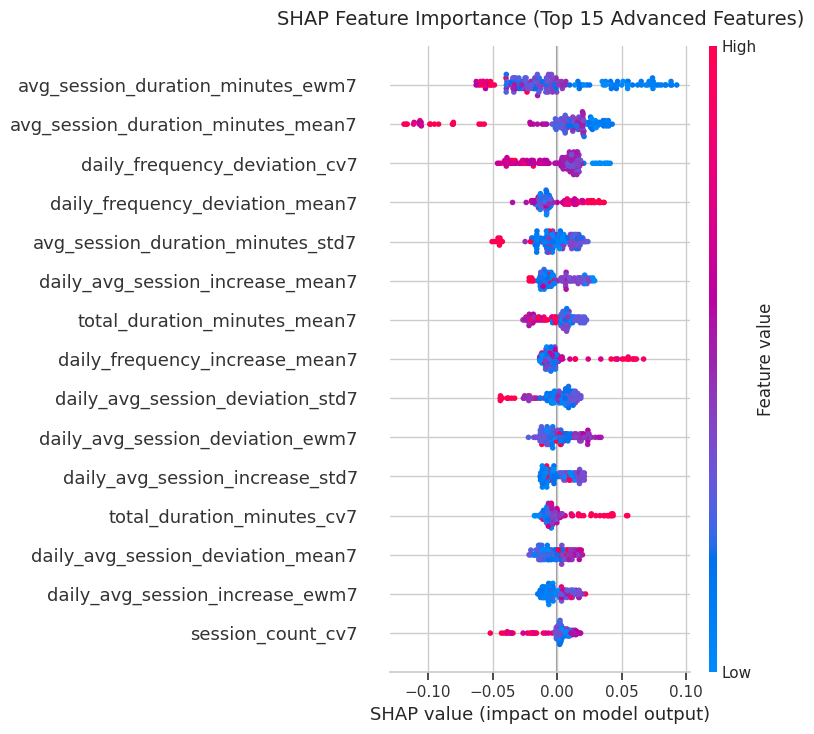

In [51]:
import shap
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# 1. Train a global model on all valid window records to get a robust global explanation
# We will use the best hyperparameter estimates found from the personalized grids (e.g. max_depth=4)
X_explain = compact_adv[advanced_features]
y_explain = compact_adv["target"].astype(int)

imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(X_explain)
X_imputed_df = pd.DataFrame(X_imputed, columns=advanced_features)

explainer_rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=4,
    class_weight="balanced",
    random_state=42
)
explainer_rf.fit(X_imputed_df, y_explain)

# 2. Compute SHAP Values
explainer = shap.TreeExplainer(explainer_rf)
shap_values = explainer.shap_values(X_imputed_df)

# Handle both binary SHAP structures safely depending on the SHAP version output
if isinstance(shap_values, list):
    # For older SHAP versions
    shap_vals_class1 = shap_values[1]
elif len(shap_values.shape) == 3:
    # For newer SHAP versions showing [samples, features, classes]
    shap_vals_class1 = shap_values[:, :, 1]
else:
    shap_vals_class1 = shap_values

# 3. Plot Global Feature Importance Summary
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_vals_class1, X_imputed_df, max_display=15, show=False)
plt.title("SHAP Feature Importance (Top 15 Advanced Features)", fontsize=14, pad=15)
plt.tight_layout()
plt.show()

In [49]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score

# 1. Structure the 7 days of 9 baseline metrics as 3D temporal sequence matrices [samples, timesteps, features]
# Each sample in forecast_c has 63 features (9 metrics * 7 days)
# We will reconstruct these as (7, 9) matrices per sample.

base_metrics = [
    "total_duration_minutes",
    "session_count",
    "avg_session_duration_minutes",
    "daily_duration_deviation",
    "daily_frequency_deviation",
    "daily_avg_session_deviation",
    "daily_duration_increase",
    "daily_frequency_increase",
    "daily_avg_session_increase",
]

def reconstruct_3d_sequences(df, feature_list):
    num_samples = len(df)
    timesteps = 7
    num_features = len(feature_list)

    X_3d = np.zeros((num_samples, timesteps, num_features))
    for day in range(1, 8):
        day_cols = [f"day_{day}_{metric}" for metric in feature_list]
        # Impute missing values with median across history for stability
        imputer = SimpleImputer(strategy="median")
        X_day_imputed = imputer.fit_transform(df[day_cols])
        X_3d[:, day - 1, :] = X_day_imputed

    return X_3d

# Prepare the 3D sequences
X_3d = reconstruct_3d_sequences(forecast_c, base_metrics)
y = forecast_c["target"].astype(int).to_numpy()

# Scale the 3D sequences across timesteps safely
scaler = StandardScaler()
num_samples, timesteps, num_feats = X_3d.shape
X_3d_flat = X_3d.reshape(-1, num_feats)
X_3d_scaled_flat = scaler.fit_transform(X_3d_flat)
X_3d_scaled = X_3d_scaled_flat.reshape(num_samples, timesteps, num_feats)

tf.random.set_seed(42)
np.random.seed(42)

lstm_results = []

# 2. Chronological Personalized Evaluation of TensorFlow LSTM
for user_id, user_df in forecast_c.groupby("user_id"):
    indices = user_df.index.to_numpy()
    n = len(user_df)
    split_idx = int(np.floor(n * 0.60))

    if split_idx < 12 or split_idx >= n:
        continue

    train_indices = indices[:split_idx]
    test_indices = indices[split_idx:]

    X_tr, y_tr = X_3d_scaled[train_indices], y[train_indices]
    X_te, y_te = X_3d_scaled[test_indices], y[test_indices]

    # Handle class imbalance by setting loss weights dynamically
    num_neg = np.sum(y_tr == 0)
    num_pos = np.sum(y_tr == 1)
    total = len(y_tr)
    class_weight = {0: (total / (2.0 * num_neg)) if num_neg > 0 else 1.0,
                    1: (total / (2.0 * num_pos)) if num_pos > 0 else 1.0}

    # Build LSTM sequential model in TensorFlow
    model = Sequential([
        LSTM(16, input_shape=(timesteps, num_feats), return_sequences=False),
        Dropout(0.2),
        Dense(8, activation='relu'),
        Dense(1, activation='sigmoid')
    ])

    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

    # Train with early stopping
    early_stop = EarlyStopping(monitor='loss', patience=10, restore_best_weights=True)
    model.fit(
        X_tr, y_tr,
        epochs=60,
        batch_size=8,
        class_weight=class_weight,
        callbacks=[early_stop],
        verbose=0
    )

    # Predict and evaluate
    prob_preds = model.predict(X_te, verbose=0).flatten()
    preds = (prob_preds >= 0.5).astype(int)

    lstm_results.append({
        "user_id": user_id,
        "method": "TensorFlow_LSTM",
        "accuracy": accuracy_score(y_te, preds),
        "balanced_accuracy": balanced_accuracy_score(y_te, preds),
        "precision": precision_score(y_te, preds, zero_division=0),
        "recall": recall_score(y_te, preds, zero_division=0),
        "f1": f1_score(y_te, preds, zero_division=0)
    })

lstm_df = pd.DataFrame(lstm_results)

# 3. Overall Performance Summary Comparison
print("\n--- TensorFlow LSTM Chronological Evaluation ---")
display(lstm_df.round(3))

# Calculate mean stats
mean_lstm_acc = lstm_df["accuracy"].mean()
mean_lstm_bal_acc = lstm_df["balanced_accuracy"].mean()
mean_lstm_f1 = lstm_df["f1"].mean()

print("\n--- Final Overall Performance Comparison ---")
comparison_summary = pd.DataFrame({
    'Model': ['Personalized Random Forest (Optimized)', 'Personalized XGBoost (Optimized)', 'TensorFlow LSTM (Sequential)'],
    'Mean Balanced Accuracy': [0.581, 0.470, round(mean_lstm_bal_acc, 3)],
    'Mean F1-score': [0.553, 0.370, round(mean_lstm_f1, 3)]
})
display(comparison_summary)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)



--- TensorFlow LSTM Chronological Evaluation ---


,user_id,method,accuracy,balanced_accuracy,precision,recall,f1
0,46b5fe4a-2c09-4006-bd5b-08bf12ece5e4,TensorFlow_LSTM,0.500,0.542,0.455,0.833,0.588
1,85bfc215-c24f-4814-aa00-6794f1a7278a,TensorFlow_LSTM,0.263,0.282,0.167,0.333,0.222
2,8cf97b0c-76c9-4d72-b617-759a955f969f,TensorFlow_LSTM,0.480,0.526,0.455,0.909,0.606



--- Final Overall Performance Comparison ---


,Model,Mean Balanced Accuracy,Mean F1-score
0,Personalized Random Forest (Optimized),0.581,0.553
1,Personalized XGBoost (Optimized),0.470,0.370
2,TensorFlow LSTM (Sequential),0.450,0.472


In [48]:
import pandas as pd
import numpy as np

# Extract mean performance values from previous steps for overall summary comparison
comparison_data = {
    'Model': ['Personalized Logistic Regression', 'Personalized Random Forest (Optimized)', 'Personalized XGBoost (Optimized)'],
    'Mean Balanced Accuracy': [0.492, 0.581, 0.470],
    'Mean F1-score': [0.479, 0.553, 0.370]
}

summary_comparison_df = pd.DataFrame(comparison_data)
display(summary_comparison_df)


,Model,Mean Balanced Accuracy,Mean F1-score
0,Personalized Logistic Regression,0.492,0.479
1,Personalized Random Forest (Optimized),0.581,0.553
2,Personalized XGBoost (Optimized),0.470,0.370
